# **AI METHODS I**
## Day II: Application of supervised learning methods.

Howdy! today we will make our first approach to machine learning models. well, we already kind of started by using imputation tool from the scikit-learn library. But! today we will learn how they work, how to use them and **WHEN TO USE THEM**.

Now, the gold question! *What is supervised learning?*

**Supervised learning** means learning from **examples where we already know the answer**. We show the computer many examples of *inputs* together with the *correct output*, and it learns a rule that maps one to the other. Then we use that rule to predict the output for **new** inputs, where we don't know the answer yet.

Think of an experienced **cost estimator**. After seeing hundreds of finished projects (size, location, materials… and their final cost), they can look at a new project and estimate its cost. Nobody gave them a formula: they *learned it from examples*. A supervised model does the same thing, only with many more examples and with maths instead of intuition.

| Term | Meaning | Example |
|---|---|---|
| **Features** (`X`) | The inputs: what we know about each example | Floor area, city, number of bedrooms |
| **Target** (`y`) | The output we want to predict (the "label") | The price of the flat |
| **Model** | The rule that maps `X` → `y`, learned from the data | "price ≈ area × price per m² in that city" |
| **Training** (`fit`) | Learning the rule from examples | Looking at 50,000 flats with known prices |
| **Prediction** (`predict`) | Applying the rule to new examples | Estimating the price of a flat that isn't on the market yet |

### Two kinds of supervised problems

| | **Regression** | **Classification** |
|---|---|---|
| The target is… | a **number** (continuous) | a **category** (a class / label) |
| Question | *"How much?"* | *"Which one?"* |
| Built-environment examples | Price of a flat, energy demand in kWh/m², construction cost, CO₂ emissions | Energy rating A/B/C, element type in a BIM model (wall / slab / column), "will this project be delayed? yes/no" |
| Today's use case | **Part A:** predict the **price** of a flat (Day 1 data) | **Part B:** predict the **energy class** of a building |

### The supervised learning workflow
```
            ┌──────────────────────────────── TRAINING DATA ───────────────────────────────┐
 DATA ──► SPLIT ──► PREPROCESS ──► FIT MODELS ──► VALIDATE (cross-validation) ──► TUNE ──┐
            │                         ▲                                                  │
            │                         └───────────── compare, improve, repeat ───────────┘
            │
            └──► TEST DATA (locked away) ─────────────────────► FINAL TEST, ONCE ──► INTERPRET & COMMUNICATE
```

### Learning goals
By the end of this notebook you will be able to:
1. Explain **train / test splits**, **overfitting**, **cross-validation**, **baselines** and **data leakage**.
2. Build **scikit-learn pipelines** that combine preprocessing (imputation, scaling, **encoding of categories**) and a model.
3. Describe the main **families of supervised models** and know **when to use which**.
4. Choose and interpret **validation metrics** for regression (MAE, RMSE, R², MAPE) and classification (accuracy, precision, recall, F1, confusion matrix).
5. Tune a model, evaluate it honestly on a test set, explain which features matter, and **save** it for later use.

### Table of contents
0. Setup and data
1. Core concepts
2. scikit-learn pipelines and encoders
3. The model zoo: types of supervised models
4. Part A – Regression: predicting the price of a flat
5. Part B – Classification: predicting the energy class of a building
6. Summary: which model, which metric?
7. Your turn
8. Conclusions and next steps

> **How to use this notebook:** run the cells from top to bottom. The whole notebook takes a couple of minutes to run; cells that train many models print how long they took.

# 0. Setup

## 0.1 Libraries

Same as Day 1 (pandas, numpy, matplotlib, seaborn, kagglehub), plus **scikit-learn** (`sklearn`), the main machine learning library in Python. scikit-learn is organised in **modules**; we will import each tool from its module the first time we use it, so you learn where things live:

| Module | Contains |
|---|---|
| `sklearn.model_selection` | Splitting data, cross-validation, hyperparameter search |
| `sklearn.preprocessing` / `sklearn.impute` | Scalers, encoders, imputers |
| `sklearn.pipeline` / `sklearn.compose` | Pipelines and column transformers |
| `sklearn.linear_model`, `.neighbors`, `.tree`, `.ensemble` | The models |
| `sklearn.metrics` | Evaluation metrics |
| `sklearn.inspection` | Tools to interpret models |

💡 **Tip – Google Colab:** uncomment and run the next cell first.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter
import joblib   # to save and load trained models

In [3]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")   # trained models will be saved here
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings (same as Day 1) ------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# The same seed everywhere: same splits, same "random" models, same results for everybody
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.2 Dataset 1: house prices (from Day 1)

We start from the **clean dataset we produced on Day 1**. This is how real projects work: the output of one step is the input of the next.

In [4]:
house_path = DATA_DIR / "house_prices_clean.csv"

if not house_path.exists():
    raise FileNotFoundError(
        f"{house_path} not found. Run the Day 1 notebook first and copy "
        "data/house_prices_clean.csv into this notebook's data/ folder."
    )

house = pd.read_csv(house_path)
print(f"House prices: {house.shape[0]:,} rows x {house.shape[1]} columns")
house.head(3)

House prices: 62,460 rows x 24 columns


,amount,amount_lakh,location,bhk,property_type,carpet_area,carpet_area_m2,super_area,efficiency,bathroom,balcony,balcony_was_missing,floor_num,total_floors,floor_ratio,facing,view_garden,view_pool,view_main_road,transaction,furnishing,ownership,parking_spaces,price_per_sqft
0,"4,200,000.000",42.000,Thane,1,Flat,500.000,46.452,700.000,0.714,1,2,False,10.000,11.000,0.909,Unknown,False,False,False,Resale,Unfurnished,Unknown,NaN,"6,000.000"
1,"9,800,000.000",98.000,Thane,2,Flat,473.000,43.943,710.196,0.666,2,2,True,3.000,22.000,0.136,East,True,False,False,Resale,Semi-Furnished,Freehold,1.000,"13,799.000"
2,"14,000,000.000",140.000,Thane,2,Flat,779.000,72.372,800.000,0.974,2,2,True,10.000,29.000,0.345,East,True,False,False,Resale,Unfurnished,Freehold,1.000,"17,500.000"


## 0.3 Dataset 2: energy efficiency of buildings

For classification we use a classic built-environment dataset: the **Energy Efficiency** dataset (Tsanas & Xifara, 2012, UCI Machine Learning Repository), also published on Kaggle.

| | |
|---|---|
| **Source** | UCI ML Repository / Kaggle [elikplim/eergy-efficiency-dataset](https://www.kaggle.com/datasets/elikplim/eergy-efficiency-dataset) |
| **Paper** | A. Tsanas, A. Xifara (2012), *Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools*, Energy and Buildings 49 |
| **Origin** | **Simulated** with Ecotect: 12 building shapes, each with different orientations and glazing configurations |
| **Unit of observation** | One row = one simulated building variant |
| **Size** | 768 rows × 10 columns, no missing values |
| **Targets** | Heating load and cooling load (kWh/m² per year) |

The columns are named `X1 … X8, Y1, Y2` in the file. We give them meaningful names:

| Code | Name | Meaning |
|---|---|---|
| X1 | `relative_compactness` | How compact the shape is (volume vs envelope). 1 = very compact |
| X2 | `surface_area` | Total envelope area (m²) |
| X3 | `wall_area` | Wall area (m²) |
| X4 | `roof_area` | Roof area (m²) |
| X5 | `overall_height` | Building height: 3.5 m (1 storey) or 7 m (2 storeys) |
| X6 | `orientation` | 2 = North, 3 = East, 4 = South, 5 = West |
| X7 | `glazing_area` | Window area as a share of floor area: 0, 10, 25 or 40% |
| X8 | `glazing_distribution` | Where the windows are: 0 = none, 1 = uniform, 2 = north, 3 = east, 4 = south, 5 = west |
| Y1 | `heating_load` | Heating demand (kWh/m²·year) |
| Y2 | `cooling_load` | Cooling demand (kWh/m²·year) |

In [5]:
energy = kh.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "elikplim/eergy-efficiency-dataset",
    "ENB2012_data.csv",
)

energy = energy.rename(columns={
    "X1": "relative_compactness",
    "X2": "surface_area",
    "X3": "wall_area",
    "X4": "roof_area",
    "X5": "overall_height",
    "X6": "orientation",
    "X7": "glazing_area",
    "X8": "glazing_distribution",
    "Y1": "heating_load",
    "Y2": "cooling_load",
})

print(f"Energy efficiency: {energy.shape[0]} rows x {energy.shape[1]} columns")
energy.head()

Energy efficiency: 768 rows x 10 columns


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_distribution,heating_load,cooling_load
0,0.980,514.500,294.000,110.250,7.000,2,0.000,0,15.550,21.330
1,0.980,514.500,294.000,110.250,7.000,3,0.000,0,15.550,21.330
2,0.980,514.500,294.000,110.250,7.000,4,0.000,0,15.550,21.330
3,0.980,514.500,294.000,110.250,7.000,5,0.000,0,15.550,21.330
4,0.900,563.500,318.500,122.500,7.000,2,0.000,0,20.840,28.280


# 1. Core concepts

Five ideas you need before training any model. Each comes with a small example.

## 1.1 Train / test split

Imagine a teacher who gives students the **exact exam questions** as homework. Everybody gets 10/10 on the exam… but did they learn anything? We can only measure learning with **questions they have not seen before**.

Models are the same. If we evaluate a model on the data it learned from, it looks great, because it may simply have **memorised** the answers. So before doing anything else, we **split** the data:

- **Training set** (usually 70–80%): the model learns from it.
- **Test set** (20–30%): locked away, used **once at the very end** to estimate how the model performs on new data.

`train_test_split` shuffles the rows randomly and splits them. Let's do it now for the house prices, and **keep this split for the whole notebook**.

Our target is the **price**. On Day 1 we saw that prices are very skewed and look like a bell curve on a log scale, so we predict the **log10 of the price**. We also remove the columns that must not be used as inputs (more on this in 1.5).

In [6]:
from sklearn.model_selection import train_test_split

# Target: log10 of the price (a price of 1,000,000 ₹ becomes 6.0, 10,000,000 ₹ becomes 7.0)
y_house = np.log10(house["amount"])

# Features: everything except the price itself and columns derived from it
X_house = house.drop(columns=["amount", "amount_lakh", "price_per_sqft", "carpet_area_m2"])

# True/False columns -> 1/0, so every model can use them as numbers
bool_columns = X_house.select_dtypes("bool").columns
X_house[bool_columns] = X_house[bool_columns].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_house, y_house,
    test_size=0.2,              # 20% for the test set
    random_state=RANDOM_STATE,  # same shuffle every time we run the notebook
)

print(f"Training set: {len(X_train):,} flats")
print(f"Test set:     {len(X_test):,} flats (locked away until section 4.7!)")

Training set: 49,968 flats
Test set:     12,492 flats (locked away until section 4.7!)


## 1.2 Underfitting and overfitting

A model can fail in two opposite ways:

| | **Underfitting** | **Good fit** | **Overfitting** |
|---|---|---|---|
| What happens | The model is too **simple** to capture the pattern | Captures the pattern, ignores the noise | The model is too **complex**: it memorises the noise |
| Training error | High | Low | **Very low** |
| Test error | High | Low | **High** |
| Analogy | A student who only learned "the answer is usually C" | A student who understood the subject | A student who memorised last year's exam |

Let's see it with a small **synthetic** example: the relation between the **window-to-wall ratio** of a façade and its **energy demand** (we invent the "true" curve and add random noise, like measurement errors). We fit three polynomial curves of increasing complexity on the training points (dark) and check them on test points (orange).

Figure saved to figures/01_under_overfitting.png


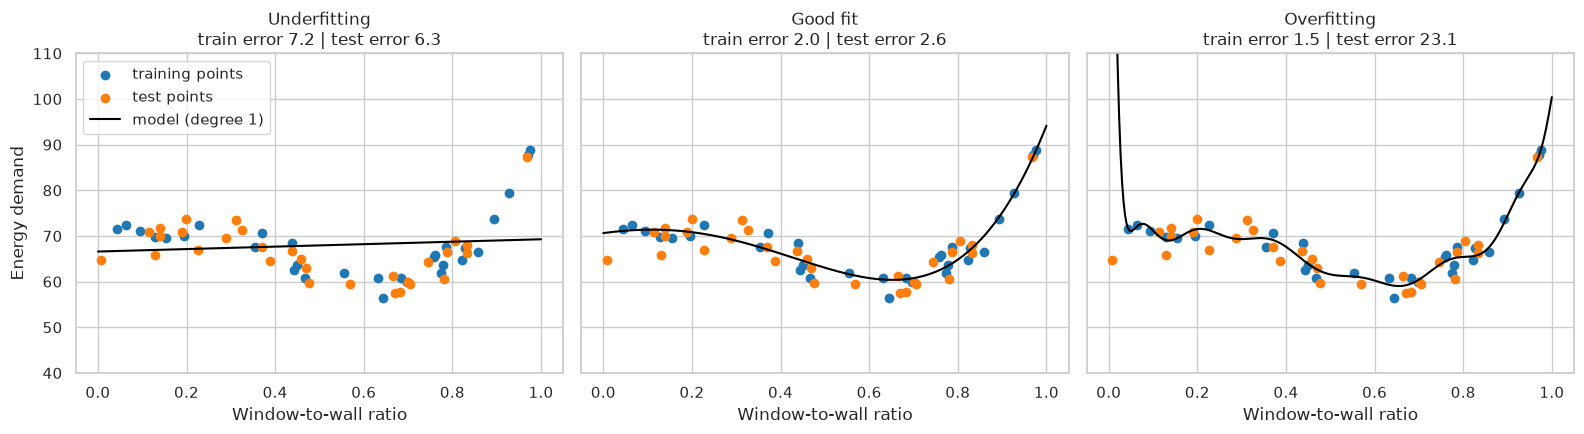

In [7]:
rng = np.random.default_rng(RANDOM_STATE)   # random number generator with a fixed seed

# Invented "true" relation + noise. x = window-to-wall ratio (0-1), y = energy demand (arbitrary units)
def true_curve(x):
    return 60 + 80 * (x - 0.35) ** 2 + 10 * np.sin(6 * x)

x_all = rng.uniform(0, 1, 60)
y_all = true_curve(x_all) + rng.normal(0, 3, 60)          # add noise
x_tr, y_tr, x_te, y_te = x_all[:30], y_all[:30], x_all[30:], y_all[30:]

x_line = np.linspace(0, 1, 300)   # points to draw the fitted curves

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, degree, label in zip(axes, [1, 4, 15], ["Underfitting", "Good fit", "Overfitting"]):
    # Fit a polynomial of the given degree to the TRAINING points only
    poly = np.polynomial.Polynomial.fit(x_tr, y_tr, degree)
    rmse_train = np.sqrt(np.mean((poly(x_tr) - y_tr) ** 2))
    rmse_test = np.sqrt(np.mean((poly(x_te) - y_te) ** 2))

    ax.scatter(x_tr, y_tr, color="tab:blue", label="training points")
    ax.scatter(x_te, y_te, color="tab:orange", label="test points")
    ax.plot(x_line, poly(x_line), color="black", label=f"model (degree {degree})")
    ax.set_ylim(40, 110)
    ax.set_title(f"{label}\ntrain error {rmse_train:.1f} | test error {rmse_test:.1f}")
    ax.set_xlabel("Window-to-wall ratio")
axes[0].set_ylabel("Energy demand")
axes[0].legend(loc="upper left")
plt.tight_layout()
save_fig("01_under_overfitting")
plt.show()

The degree-15 curve passes almost exactly through the training points (lowest training error) but wiggles wildly between them, so its **test error is the worst**. This is the most important lesson of the day:

> **A model is only as good as its performance on data it has never seen.**

Every model has some **complexity knob** (the polynomial degree here, the depth of a tree, the number of neighbours in KNN…). Too little → underfitting; too much → overfitting. These knobs are called **hyperparameters**, and choosing them well is part of the job (section 4.6).

## 1.3 Cross-validation

If we need data the model has not seen to compare models and choose hyperparameters, can we use the test set? **No!** If we pick the model that does best on the test set, the test set is no longer "unseen": we would be fooling ourselves. The test set is for the **final** check only.

Instead we use **K-fold cross-validation** on the training set:
1. Split the training set into K parts (*folds*), e.g. K = 5.
2. Train on 4 folds, validate on the 5th.
3. Repeat 5 times, so each fold is used once for validation.
4. Report the **average** score (and its spread).

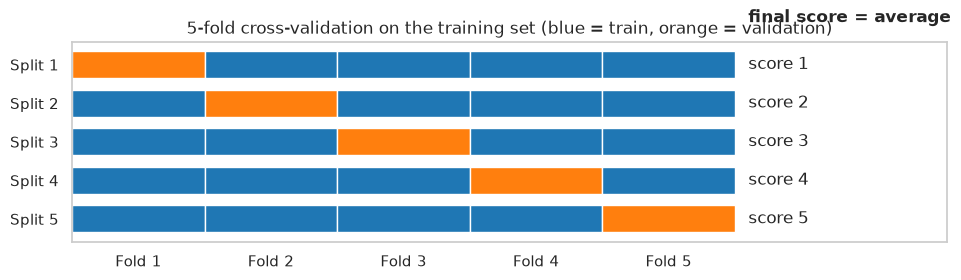

In [8]:
# A small diagram of 5-fold cross-validation
k = 5
fig, ax = plt.subplots(figsize=(10, 3))
for split in range(k):
    for fold in range(k):
        is_validation = fold == split
        ax.barh(y=split, width=1, left=fold, height=0.7, edgecolor="white",
                color="tab:orange" if is_validation else "tab:blue")
    ax.text(k + 0.1, split, f"score {split + 1}", va="center")
ax.text(k + 0.1, -1.1, "final score = average", fontweight="bold")
ax.set_yticks(range(k), [f"Split {i + 1}" for i in range(k)])
ax.set_xticks([i + 0.5 for i in range(k)], [f"Fold {i + 1}" for i in range(k)])
ax.invert_yaxis()
ax.set_xlim(0, k + 1.6)
ax.grid(False)
ax.set_title("5-fold cross-validation on the training set (blue = train, orange = validation)")
plt.tight_layout()
plt.show()

Why is this better than a single validation split? With one split, the score depends on *which* rows happened to land in the validation part (lucky or unlucky). Averaging over 5 splits is more **stable**, and the **standard deviation** of the 5 scores tells us how much the score could change by chance.

## 1.4 Baselines

Before celebrating a score, ask: *what score would a "dumb" model get?* A **baseline** is the simplest possible prediction:
- **Regression:** always predict the **mean** of the training targets.
- **Classification:** always predict the **most frequent class**.

scikit-learn has these as `DummyRegressor` and `DummyClassifier`. If your model cannot clearly beat the baseline, it has not learned anything useful.

`cross_validate` runs cross-validation for us: it gives back the score of each of the 5 folds.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# The 5-fold splitter we will use for all regression models. shuffle=True: rows are shuffled first
cv_regression = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = DummyRegressor(strategy="mean")   # always predicts the average log-price
results = cross_validate(baseline, X_train, y_train, cv=cv_regression, scoring="r2")

print("R² of each fold:", results["test_score"].round(3))
print(f"Average R²: {results['test_score'].mean():.3f}")

R² of each fold: [-0. -0. -0. -0. -0.]
Average R²: -0.000


The baseline has an **R² of 0** (by definition, see section 4.2). Every real model must do clearly better than this.

## 1.5 Data leakage

**Data leakage** happens when information that would **not be available at prediction time** sneaks into the training data. The model then looks brilliant in the notebook and fails in the real world.

On Day 1 we found that `price_per_sqft` is literally `amount / super_area`. So `log(price) = log(price_per_sqft) + log(super_area)`: if we give the model the price per sqft, it doesn't need to learn anything. Let's see what happens:

In [10]:
from sklearn.linear_model import LinearRegression

# Only the training rows, and only rows where both columns are known
leaky = house.loc[X_train.index, ["price_per_sqft", "super_area"]].dropna()
y_leaky = y_train.loc[leaky.index]

with_leak = np.log10(leaky[["price_per_sqft", "super_area"]])
without_leak = np.log10(leaky[["super_area"]])

r2_with = cross_validate(LinearRegression(), with_leak, y_leaky, cv=cv_regression, scoring="r2")["test_score"].mean()
r2_without = cross_validate(LinearRegression(), without_leak, y_leaky, cv=cv_regression, scoring="r2")["test_score"].mean()

print(f"With price_per_sqft:    R² = {r2_with:.4f}   <- 'perfect' model, too good to be true!")
print(f"Without price_per_sqft: R² = {r2_without:.4f}")

With price_per_sqft:    R² = 1.0000   <- 'perfect' model, too good to be true!
Without price_per_sqft: R² = 0.6136


A **perfect score is a red flag**, not a reason to celebrate. In real life, when a client asks *"how much is this flat worth?"*, we don't know its price per sqft, because that is computed **from the price**!

⚠️ **Watch out – the subtle kind of leakage:** leakage also happens when we fit preprocessing steps (imputers, scalers, encoders) on the **whole** dataset before splitting: the training data then "knows" something about the test data (e.g. its median). The fix is to fit every preprocessing step **on the training data only**. Doing this by hand is error-prone… which is exactly why scikit-learn has **pipelines**.

# 2. scikit-learn pipelines and encoders

## 2.1 The scikit-learn API: fit, transform, predict

On Day 1 we already used a scikit-learn tool: `SimpleImputer`. Every object in scikit-learn follows the same small set of methods, which makes them easy to combine:

| Type of object | Examples | Methods | What it does |
|---|---|---|---|
| **Transformer** | `SimpleImputer`, `StandardScaler`, `OneHotEncoder` | `fit()` + `transform()` (or `fit_transform()`) | **Learns** something from the data (a median, a mean, a list of categories) and then **changes** the data |
| **Estimator / model** | `LinearRegression`, `RandomForestClassifier` | `fit()` + `predict()` | **Learns** the relation between `X` and `y` and **predicts** `y` for new `X` |

The golden rule: **`fit` only on training data**, then `transform` / `predict` on anything.

## 2.2 The problem pipelines solve

Let's train a small model on three numeric columns. They contain missing values (so we need an **imputer**), and they have very different scales (areas in the thousands, bathrooms 1–5), so we use a **scaler**. `StandardScaler` rescales each column to mean 0 and standard deviation 1.

**Version 1: by hand.**

In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

small_features = ["carpet_area", "bathroom", "bhk"]

# 1) Create the tools
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
model = LinearRegression()

# 2) FIT everything on the training data, step by step
X_tr_step1 = imputer.fit_transform(X_train[small_features])   # learn medians, fill gaps
X_tr_step2 = scaler.fit_transform(X_tr_step1)                  # learn means/stds, rescale
model.fit(X_tr_step2, y_train)

# 3) Apply the SAME steps to the test data, with transform only (never fit on test!)
X_te_step1 = imputer.transform(X_test[small_features])
X_te_step2 = scaler.transform(X_te_step1)
predictions = model.predict(X_te_step2)

print(f"R² by hand: {r2_score(y_test, predictions):.4f}")

R² by hand: 0.5139


It works, but every step must be repeated in the right order, with `fit_transform` in one place and `transform` in the other. Forget one, or use `fit_transform` on the test data by mistake, and you get wrong results or leakage. Now imagine doing this inside 5-fold cross-validation…

**Version 2: with a `Pipeline`.** A pipeline chains the steps into **one object** that behaves like a model: one `fit`, one `predict`.

In [12]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # (name, step)
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

pipe.fit(X_train[small_features], y_train)               # fits imputer -> scaler -> model on train
predictions = pipe.predict(X_test[small_features])       # transforms test with what was learned, then predicts

print(f"R² with a pipeline: {r2_score(y_test, predictions):.4f}   (identical, with much less code)")

R² with a pipeline: 0.5139   (identical, with much less code)


(We just peeked at the test set to show that both versions are identical. From now on, the test set stays locked until section 4.7.)

## 2.3 Encoding categorical variables

Models only understand **numbers**. Columns like `location`, `facing` or `furnishing` contain text, so we must **encode** them. First we need to know what *kind* of category we have:

| Kind | Meaning | Examples in our data |
|---|---|---|
| **Nominal** | Categories with **no natural order** | `location` (Mumbai is not "more" than Pune), `facing`, `ownership`, energy `orientation` |
| **Ordinal** | Categories with a **meaningful order** | `furnishing`: Unfurnished < Semi-Furnished < Furnished. Energy class A < B < C |

Let's look at the main encoders on 5 example rows:

In [13]:
example = X_train[["furnishing", "facing", "location"]].sample(5, random_state=RANDOM_STATE)
example

,furnishing,facing,location
55590,Semi-Furnished,East,Tirupati
26545,Furnished,Unknown,Pune
51059,Unfurnished,North,Ranchi
111,Unfurnished,North-East,Thane
28,Unfurnished,East,Thane


### One-hot encoding: `OneHotEncoder`

Creates **one 0/1 column per category**. A flat facing East gets a 1 in the `facing_East` column and 0 everywhere else. No order is invented: each category is simply "present" or "absent". This is the **default choice for nominal categories**.

In [14]:
from sklearn.preprocessing import OneHotEncoder

# sparse_output=False -> a normal table instead of a compressed "sparse" matrix
# .set_output(transform="pandas") -> get a DataFrame back, with readable column names
onehot = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
onehot.fit_transform(example[["facing"]])

,facing_East,facing_North,facing_North-East,facing_Unknown
55590,1.000,0.000,0.000,0.000
26545,0.000,0.000,0.000,1.000
51059,0.000,1.000,0.000,0.000
111,0.000,0.000,1.000,0.000
28,1.000,0.000,0.000,0.000


⚠️ **Watch out:** one-hot encoding creates **many columns** when there are many categories: `location` has 81 cities → 81 columns. That is fine for 81, but not for 10,000 (e.g. the `society` names we dropped on Day 1). Also, a city that appears in the test data but never in training would crash the encoder; `handle_unknown="ignore"` turns it into all zeros instead.

### Ordinal encoding: `OrdinalEncoder`

Replaces each category with an **integer**. It is the right choice when the order is real, and we must **tell the encoder the order**: otherwise it uses alphabetical order! For `furnishing` we place `Unknown` (not in the list) at -1: on Day 1 we saw that listings with missing information tend to be the cheapest.

In [15]:
from sklearn.preprocessing import OrdinalEncoder

furnishing_order = ["Unfurnished", "Semi-Furnished", "Furnished"]

ordinal = OrdinalEncoder(
    categories=[furnishing_order],          # the order we want: 0, 1, 2
    handle_unknown="use_encoded_value",     # categories not in the list...
    unknown_value=-1,                       # ...("Unknown") become -1
).set_output(transform="pandas")

pd.concat([example["furnishing"], ordinal.fit_transform(example[["furnishing"]])], axis=1, keys=["text", "encoded"])

,text,encoded
,furnishing,furnishing
55590,Semi-Furnished,1.000
26545,Furnished,2.000
51059,Unfurnished,0.000
111,Unfurnished,0.000
28,Unfurnished,0.000


### "Label encoding": `LabelEncoder`

When people say "label encoding" they usually mean: give each category an integer, in alphabetical order. scikit-learn's `LabelEncoder` does exactly that, but note its name: it is designed for **labels**, i.e. the **target `y`** of a classification problem (we use it in Part B), **not for features**.

Here is what goes wrong if we use it on a nominal feature:

In [16]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
codes = label_encoder.fit_transform(X_train["facing"])

# Show the integer that each orientation received
pd.Series(range(len(label_encoder.classes_)), index=label_encoder.classes_, name="code")

East          0
North         1
North-East    2
North-West    3
South         4
South-East    5
South-West    6
Unknown       7
West          8
Name: code, dtype: int64

The codes are alphabetical. A linear model would now believe that **West (8) is "eight times more" than East (0)**, and that North-East (2) lies "between" North (1) and North-West (3). These relations are **invented**: the encoding creates a fake order. For a nominal feature, this can badly mislead some models (we measure the damage in section 4.3).

### Target encoding: `TargetEncoder`

A cleverer option for nominal columns with **many** categories: replace each category with the **average target** of that category (e.g. each city with its average log-price). One column instead of 81, and the numbers are meaningful.

⚠️ **Watch out:** it uses the target, so it can leak. scikit-learn's `TargetEncoder` protects against this with an internal cross-validation when you call `fit_transform`.

In [17]:
from sklearn.preprocessing import TargetEncoder

target_encoder = TargetEncoder().set_output(transform="pandas")
city_encoded = target_encoder.fit_transform(X_train[["location"]], y_train)

# Show the learned value (average log10-price) for a few cities
learned = pd.Series(target_encoder.encodings_[0], index=target_encoder.categories_[0], name="encoded value")
learned.sort_values(ascending=False).head(5)

Gurgaon     7.257
Mumbai      7.176
Panchkula   7.128
New Delhi   7.089
Hyderabad   7.005
Name: encoded value, dtype: float64

### Which encoder should I use?

| Kind of column | Linear models, KNN | Tree-based models (tree, random forest, gradient boosting) |
|---|---|---|
| **Nominal, few categories** | **One-hot** | One-hot (or ordinal: trees are more tolerant of fake orders) |
| **Nominal, many categories** | One-hot, or **target encoding** | One-hot, ordinal or target encoding |
| **Ordinal** | **Ordinal** with the right order | **Ordinal** with the right order |
| **Target `y`** (classification) | `LabelEncoder` (or keep the strings: scikit-learn accepts text labels) | same |

## 2.4 `ColumnTransformer`: different preprocessing for different columns

Real datasets mix numeric and categorical columns, and each kind needs its own preprocessing:

| Columns | Preprocessing |
|---|---|
| **Numeric** | Fill missing values (median) → scale |
| **Nominal categorical** | Fill missing values (most frequent) → one-hot encode |
| **Ordinal categorical** | Ordinal encode with the correct order |

A `ColumnTransformer` applies each mini-pipeline to its own list of columns and glues the results together side by side.

In [18]:
from sklearn.compose import ColumnTransformer

numeric_features = X_train.select_dtypes("number").columns.tolist()
ordinal_features = ["furnishing"]
nominal_features = [c for c in X_train.columns if c not in numeric_features + ordinal_features]

print("Numeric:", numeric_features)
print("Nominal:", nominal_features)
print("Ordinal:", ordinal_features)

Numeric: ['bhk', 'carpet_area', 'super_area', 'efficiency', 'bathroom', 'balcony', 'balcony_was_missing', 'floor_num', 'total_floors', 'floor_ratio', 'view_garden', 'view_pool', 'view_main_road', 'parking_spaces']
Nominal: ['location', 'property_type', 'facing', 'transaction', 'ownership']
Ordinal: ['furnishing']


In [19]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

ordinal_pipeline = Pipeline([
    ("encoder", OrdinalEncoder(categories=[furnishing_order],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),   # (name, transformer, columns)
    ("nom", nominal_pipeline, nominal_features),
    ("ord", ordinal_pipeline, ordinal_features),
])

# The full pipeline: preprocessing + model, in ONE object
full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression()),
])

full_pipeline   # in Jupyter this shows an interactive diagram: click on the boxes to expand them

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If 

We can fit it like any model and look inside it with `named_steps`. After preprocessing, our 20 original columns became many more, because of one-hot encoding:

In [20]:
full_pipeline.fit(X_train, y_train)

feature_names = full_pipeline.named_steps["preprocess"].get_feature_names_out()
print(f"{X_train.shape[1]} original columns -> {len(feature_names)} columns after preprocessing")
print("A few of them:", list(feature_names[:3]), "...", list(feature_names[20:23]))

20 original columns -> 115 columns after preprocessing
A few of them: ['num__bhk', 'num__carpet_area', 'num__super_area'] ... ['nom__location_Bangalore', 'nom__location_Belgaum', 'nom__location_Bhiwadi']


## 2.5 Why pipelines matter

1. **No leakage in cross-validation.** When we pass a pipeline to `cross_validate`, the imputer, scaler and encoders are re-fitted **inside each fold**, on that fold's training part only.
2. **Swap models with one line.** `full_pipeline.set_params(model=RandomForestRegressor())` keeps all the preprocessing and changes only the model.
3. **Tune everything together.** Each step's settings get a name `step__parameter`, e.g. `model__max_depth` or `preprocess__num__imputer__strategy`, which we can tune in a grid search (section 4.6).
4. **Save and reuse as one object.** The saved file contains the medians, the categories, the scaling *and* the model: you can give it a raw row of data and get a prediction (section 4.9).

## 2.6 A reusable helper

We will train many models on two datasets, so we wrap the pipeline construction into a function. One detail: **linear models and KNN need scaling** (they compare or combine columns with different units), while **tree-based models don't** (they only ask questions like *"is the area > 1,200?"*, which don't depend on the scale).

In [21]:
def make_pipeline_for(model, numeric, nominal, ordinal=None, scale=True, nominal_encoder=None):
    # Build preprocessing + model as one Pipeline.
    #   model           : any scikit-learn model
    #   numeric         : list of numeric columns (imputed with the median, optionally scaled)
    #   nominal         : list of nominal categorical columns (one-hot encoded by default)
    #   ordinal         : dict {column: [categories in order]} for ordinal columns
    #   scale           : True for linear models / KNN, False for trees
    #   nominal_encoder : replace the default OneHotEncoder (e.g. OrdinalEncoder, TargetEncoder)
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    if nominal_encoder is None:
        nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    transformers = [
        ("num", Pipeline(numeric_steps), numeric),
        ("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", nominal_encoder)]), nominal),
    ]
    if ordinal:
        transformers.append(("ord", OrdinalEncoder(categories=list(ordinal.values()),
                                                   handle_unknown="use_encoded_value",
                                                   unknown_value=-1), list(ordinal.keys())))

    return Pipeline([("preprocess", ColumnTransformer(transformers)), ("model", model)])


# Shortcut for the house data: same columns every time
def house_pipeline(model, scale=True, nominal_encoder=None):
    return make_pipeline_for(model, numeric_features, nominal_features,
                             ordinal={"furnishing": furnishing_order},
                             scale=scale, nominal_encoder=nominal_encoder)

## 2.7 Saving and loading models

A trained pipeline can be saved to a file with `joblib` and loaded again later (in another notebook, a web app, a Grasshopper script…) without retraining. We do this in section 4.9 for our final model.

```python
joblib.dump(pipeline, "models/my_model.joblib")   # save
pipeline = joblib.load("models/my_model.joblib")  # load
```

# 3. The model zoo: types of supervised models

There are dozens of supervised models, but a handful of **families** cover most practical needs. All of them exist in a **regression** version (predict a number) and a **classification** version (predict a class).

### Linear models: `LinearRegression`, `Ridge`, `Lasso`, `LogisticRegression`
- **Idea:** the prediction is a **weighted sum** of the features: `price ≈ w₁·area + w₂·bathrooms + … + b`. Training finds the best weights.
- **Ridge / Lasso** add a penalty that keeps the weights small (*regularisation*), which reduces overfitting. Lasso can set weights to exactly 0 (automatic feature selection).
- **Logistic regression** is the classification version: a weighted sum turned into a probability.
- **Strengths:** fast, very **interpretable** (each weight has a meaning), works with little data.
- **Weaknesses:** can only draw **straight lines / flat planes**; misses non-linear effects and interactions unless you create them by hand.
- **Needs scaling:** yes (for regularisation and to compare weights).

### K-Nearest Neighbours: `KNeighborsRegressor`, `KNeighborsClassifier`
- **Idea:** *"tell me who your neighbours are"*. To predict a new flat, find the K most **similar** flats in the training data and average their prices (or take the majority class).
- **Strengths:** simple, no training phase, captures any shape.
- **Weaknesses:** slow predictions on big datasets, sensitive to irrelevant features and to the **scale** of the features, struggles with many features.
- **Needs scaling:** yes, absolutely (distances!).

### Decision tree: `DecisionTreeRegressor`, `DecisionTreeClassifier`
- **Idea:** a flowchart of **yes/no questions**: *"Is the city New Delhi? Is the area > 1,200 sqft?"*. Each leaf gives a prediction.
- **Strengths:** **readable** (you can draw it), handles non-linear relations and interactions, no scaling needed.
- **Weaknesses:** a single deep tree **overfits** very easily; small changes in the data can change the whole tree.
- **Key hyperparameter:** `max_depth` (how many questions in a row).

### Random forest: `RandomForestRegressor`, `RandomForestClassifier`
- **Idea:** train **hundreds of trees**, each on a random sample of the rows and features, and **average** their predictions (*bagging*). The "wisdom of the crowd": individual trees overfit in different ways, and their errors cancel out.
- **Strengths:** accurate out of the box, robust, few settings to tune.
- **Weaknesses:** slower and heavier than one tree, less interpretable, cannot predict beyond the range of the training data.

### Gradient boosting: `HistGradientBoostingRegressor`, `HistGradientBoostingClassifier`
- **Idea:** also many trees, but built **one after another**: each new small tree corrects the errors of the previous ones (*boosting*).
- **Strengths:** usually the **most accurate** model for **tabular data** (spreadsheets, BIM schedules…). scikit-learn's "Hist" version is **fast** on large data and **handles missing values** by itself. (Popular alternatives: XGBoost, LightGBM, CatBoost.)
- **Weaknesses:** more hyperparameters to tune, less interpretable.

### Others (briefly)
- **Support Vector Machines (SVM):** powerful on small/medium datasets, but slow on large ones and harder to tune.
- **Neural networks:** the best choice for **images, text and sound** (Day 4: computer vision). For tabular data like ours, tree ensembles usually do as well or better with much less effort.

Let's **see** how each family "thinks", by fitting them on the small synthetic dataset from section 1.2:

Figure saved to figures/02_model_families.png


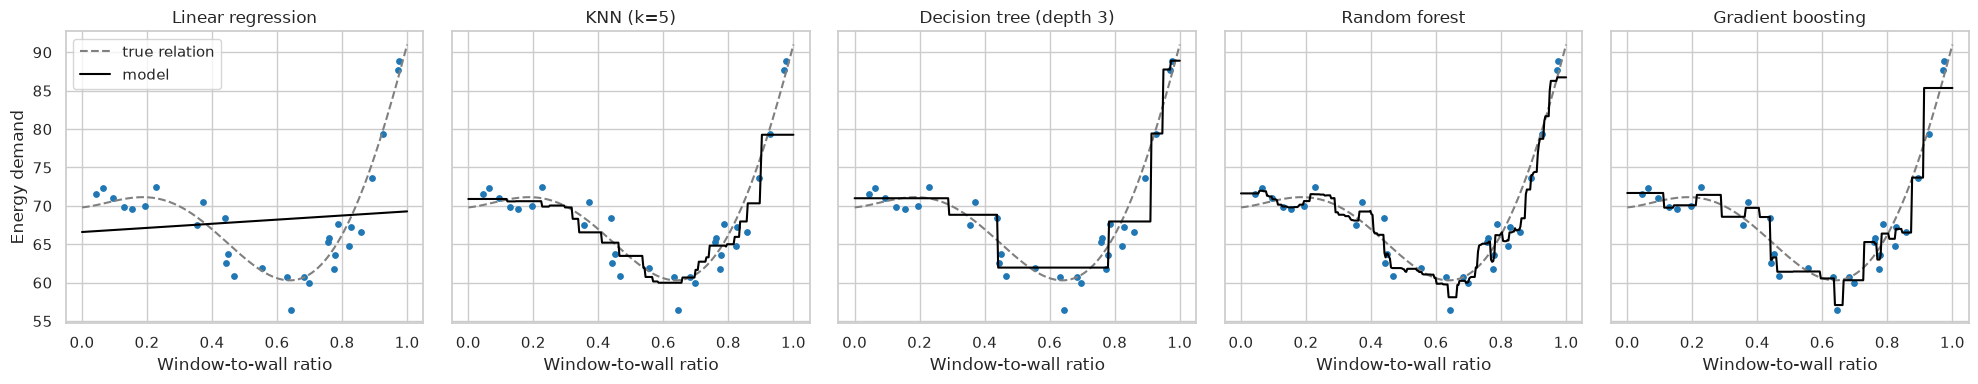

In [22]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

toy_models = {
    "Linear regression": LinearRegression(),
    "KNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    "Decision tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingRegressor(min_samples_leaf=3, random_state=RANDOM_STATE),
}

# scikit-learn expects X as a 2D table: reshape(-1, 1) turns [x1, x2, ...] into [[x1], [x2], ...]
X_toy, X_line = x_tr.reshape(-1, 1), x_line.reshape(-1, 1)

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (name, toy_model) in zip(axes, toy_models.items()):
    toy_model.fit(X_toy, y_tr)
    ax.scatter(x_tr, y_tr, color="tab:blue", s=15)
    ax.plot(x_line, true_curve(x_line), color="grey", linestyle="--", label="true relation")
    ax.plot(x_line, toy_model.predict(X_line), color="black", label="model")
    ax.set_title(name)
    ax.set_xlabel("Window-to-wall ratio")
axes[0].set_ylabel("Energy demand")
axes[0].legend(loc="upper left")
plt.tight_layout()
save_fig("02_model_families")
plt.show()

Look at the **shape** of each prediction:
- **Linear**: a straight line. It cannot follow the curve (underfitting).
- **KNN**: follows the local average of the neighbours; a bit jumpy.
- **Decision tree**: **steps** (each leaf predicts one constant value).
- **Random forest**: many steps averaged → a smoother staircase.
- **Gradient boosting**: also step-like, built by successive corrections.

### Which model when? A cheat sheet

| Model | Data size | Non-linear relations | Interpretability | Training speed | Needs scaling | Handles missing values | Typical AEC use |
|---|---|---|---|---|---|---|---|
| **Linear / Ridge / Logistic** | Small to huge | No (unless engineered) | **High** | **Very fast** | Yes | No | First baseline, explaining effects to a client ("+1 m² adds X €") |
| **KNN** | Small / medium | Yes | Medium (similar examples) | No training, slow predictions | **Yes** | No | "Find the most similar past projects" |
| **Decision tree** | Small / medium | Yes | **High** (a flowchart) | Fast | No | Partly | Design rules, communicating with non-experts |
| **Random forest** | Medium / large | Yes | Low (feature importance) | Medium | No | No | Robust default for tabular data |
| **Gradient boosting** | Medium / large | Yes | Low (feature importance) | Fast (Hist version) | No | **Yes** | Best accuracy on tabular data: cost, energy, BIM schedules |
| **Neural networks** | Large | Yes | Very low | Slow | Yes | No | Images, point clouds, text (Day 4) |

💡 **Tip – a practical recipe:** start with a **baseline**, then a **linear model** (fast, interpretable), then a **tree ensemble** (random forest or gradient boosting). Only go further if the gain is worth the extra complexity.

# 4. Part A – Regression: predicting the price of a flat

**Use case:** a developer or an architect wants a quick estimate of the market value of a flat from its characteristics (size, typology, city, floor, orientation…), for example to test design options in an early feasibility study.

We already have everything we need: the split (1.1), the target (log10 of the price), and the preprocessing (2.4–2.6).

## 4.1 Regression metrics: how do we measure the error?

| Metric | In words | Units | Good value | Notes |
|---|---|---|---|---|
| **MAE** – Mean Absolute Error | The average size of the errors | Same as the target (₹) | Close to 0 | Easy to explain: *"on average we are off by X"* |
| **RMSE** – Root Mean Squared Error | Like MAE, but big errors count much more (they are squared) | Same as the target | Close to 0 | Use when **big errors are especially bad** |
| **R²** – Coefficient of determination | Share of the variation in the target that the model explains | None | 1 = perfect, 0 = as good as the baseline mean | Good for **comparing models** on the same data; can be negative for terrible models |
| **MAPE** – Mean Absolute Percentage Error | The average error as a **percentage** of the true value | % | Close to 0% | Intuitive for prices: *"on average we are off by 15%"* |

Because we predict the **log10** of the price, the model's raw errors are in "log units", which are hard to interpret. So we write a helper that converts predictions back to **₹ Lakh** before computing MAE, RMSE and MAPE.

In [23]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error


def regression_report(y_true_log, y_pred_log):
    # Compute the main regression metrics. Inputs are log10(price in ₹).
    # R² is computed on the log scale (what the model optimises),
    # the other metrics on real prices in ₹ Lakh (what humans understand).
    true_lakh = 10 ** np.asarray(y_true_log) / 1e5
    pred_lakh = 10 ** np.asarray(y_pred_log) / 1e5
    return pd.Series({
        "R² (log scale)": r2_score(y_true_log, y_pred_log),
        "MAE (₹ Lakh)": mean_absolute_error(true_lakh, pred_lakh),
        "RMSE (₹ Lakh)": root_mean_squared_error(true_lakh, pred_lakh),
        "MAPE (%)": mean_absolute_percentage_error(true_lakh, pred_lakh) * 100,
    })


# Example: the "dumb" baseline that always predicts the average log-price, evaluated on the training set
regression_report(y_train, np.full(len(y_train), y_train.mean()))

R² (log scale)    0.000
MAE (₹ Lakh)     50.665
RMSE (₹ Lakh)    88.985
MAPE (%)         62.173
dtype: float64

The baseline is off by about **₹50 Lakh** and **~60%** on average. That's our reference point.

During cross-validation we use scikit-learn's built-in **scorers**. For historical reasons, error scorers are **negative** (`neg_mean_absolute_error`), because scikit-learn always assumes "bigger is better". We flip the sign back when we show them.

The MAE on the log10 scale has a neat interpretation: an error of `0.1` in log10 means a factor of `10^0.1 = 1.26`, i.e. **about 26% too high or too low**.

## 4.2 Comparing models with cross-validation

We write a helper that cross-validates a dictionary of pipelines and collects the mean and standard deviation of each metric, plus the training time.

In [24]:
def compare_models(pipelines, X, y, cv, scoring):
    # Cross-validate every pipeline and return one row of results per model.
    #   scoring: dict {display name: scikit-learn scorer name}
    rows = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)  # n_jobs=-1: use all CPU cores
        row = {"model": name}
        for metric, scorer in scoring.items():
            scores = res[f"test_{metric}"]
            if scorer.startswith("neg_"):        # flip "negative errors" back to positive
                scores = -scores
            row[f"{metric} mean"] = scores.mean()
            row[f"{metric} std"] = scores.std()
        row["fit time (s)"] = res["fit_time"].mean()
        rows.append(row)
        print(f"{name:<22} done in {time.time() - start:5.1f} s")
    return pd.DataFrame(rows).set_index("model")


regression_scoring = {"R²": "r2", "MAE (log10)": "neg_mean_absolute_error"}

## 4.3 Experiment: does the encoder matter?

Before comparing model families, let's test what we said in section 2.3. We train a **linear model** and a **tree-based model**, each with three different encodings of the nominal columns (`location`, `facing`, …):
- **One-hot** (correct for nominal data)
- **Ordinal** (alphabetical integers: a **fake order**, like `LabelEncoder`)
- **Target** encoding

In [25]:
from sklearn.linear_model import Ridge

encoders = {
    "one-hot": None,   # None = the default OneHotEncoder of our helper
    "ordinal (fake order)": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "target": TargetEncoder(),
}

encoder_pipelines = {}
for encoder_name, encoder in encoders.items():
    encoder_pipelines[f"Ridge + {encoder_name}"] = house_pipeline(Ridge(), nominal_encoder=encoder)
    encoder_pipelines[f"GradBoost + {encoder_name}"] = house_pipeline(
        HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False, nominal_encoder=encoder)

encoder_results = compare_models(encoder_pipelines, X_train, y_train, cv_regression, {"R²": "r2"})
encoder_results[["R² mean", "R² std"]]

Ridge + one-hot        done in   1.7 s
GradBoost + one-hot    done in   4.0 s
Ridge + ordinal (fake order) done in   1.1 s
GradBoost + ordinal (fake order) done in   1.7 s
Ridge + target         done in   0.3 s
GradBoost + target     done in   0.8 s


,R² mean,R² std
model,,
Ridge + one-hot,0.782,0.003
GradBoost + one-hot,0.843,0.003
Ridge + ordinal (fake order),0.631,0.004
GradBoost + ordinal (fake order),0.837,0.003
Ridge + target,0.722,0.005
GradBoost + target,0.814,0.012


**Reading the results:**
- For the **linear model**, the encoding makes a **big difference**: with fake integer codes it has to believe that the price changes *linearly* from "Agra" (code 0) to "Zirakpur" (code 80), which is nonsense, and R² drops by about 0.15. One-hot encoding is clearly the best here; target encoding (one number per city) lies in between.
- The **tree-based model** barely cares: it can split the codes into any groups (*"code < 12 or code between 40 and 45"*), so a fake order hurts much less.

From now on we use **one-hot** encoding, the safe default.

## 4.4 The model zoo on house prices

Now the main comparison: every model family, with the **same** preprocessing, the **same** 5 folds and the **same** metrics. Remember: linear models and KNN get scaling (`scale=True`), tree-based models don't.

In [26]:
regression_pipelines = {
    "Baseline (mean)": house_pipeline(DummyRegressor()),
    "Linear regression": house_pipeline(LinearRegression()),
    "Ridge": house_pipeline(Ridge(alpha=1.0)),
    "KNN (k=10)": house_pipeline(KNeighborsRegressor(n_neighbors=10)),
    "Decision tree": house_pipeline(DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE), scale=False),
    "Random forest": house_pipeline(RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                                          random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": house_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
}

regression_results = compare_models(regression_pipelines, X_train, y_train, cv_regression, regression_scoring)

# Typical % error implied by the log10 MAE (see 4.1)
regression_results["≈ typical error (%)"] = (10 ** regression_results["MAE (log10) mean"] - 1) * 100
regression_results.sort_values("R² mean", ascending=False)

Baseline (mean)        done in   0.3 s
Linear regression      done in   1.4 s
Ridge                  done in   0.3 s
KNN (k=10)             done in   2.8 s
Decision tree          done in   0.7 s
Random forest          done in  36.4 s
Gradient boosting      done in   2.7 s


,R² mean,R² std,MAE (log10) mean,MAE (log10) std,fit time (s),≈ typical error (%)
model,,,,,,
Random forest,0.849,0.003,0.090,0.000,35.732,22.990
Gradient boosting,0.843,0.003,0.095,0.001,2.430,24.489
Ridge,0.782,0.003,0.111,0.001,0.176,29.085
Linear regression,0.782,0.003,0.111,0.001,1.231,29.083
Decision tree,0.744,0.004,0.122,0.000,0.541,32.458
KNN (k=10),0.723,0.002,0.125,0.001,0.119,33.379
Baseline (mean),-0.000,0.000,0.245,0.003,0.142,75.967


Figure saved to figures/03_regression_model_comparison.png


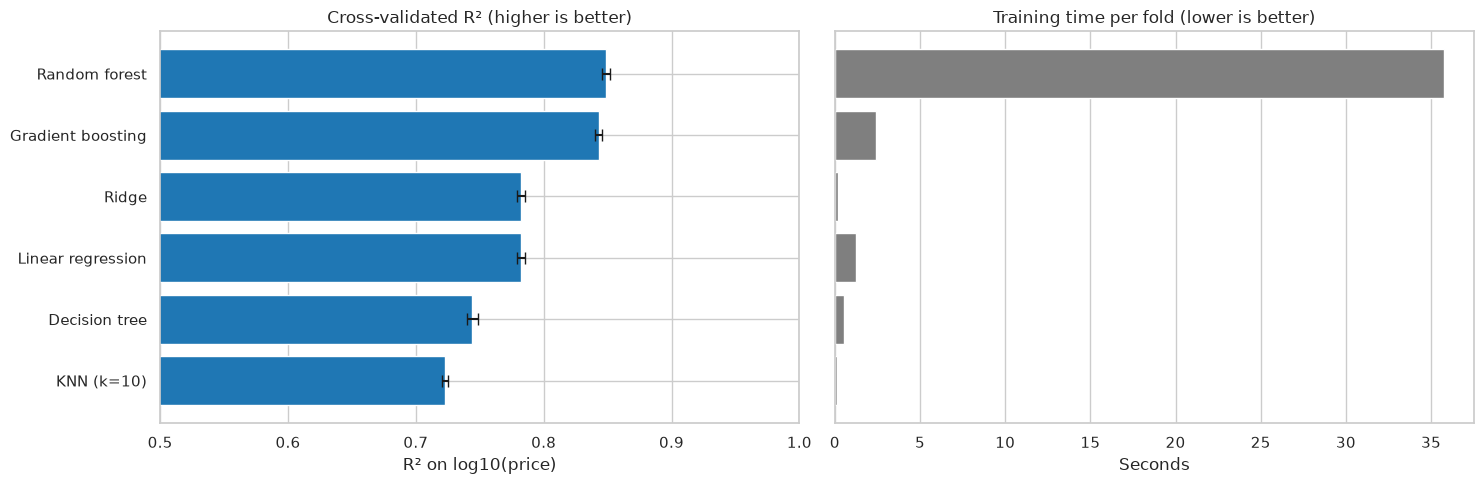

In [27]:
plot_data = regression_results.drop(index="Baseline (mean)").sort_values("R² mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# xerr = error bars of +/- one standard deviation across the 5 folds
axes[0].barh(plot_data.index, plot_data["R² mean"], xerr=plot_data["R² std"], color="tab:blue", capsize=4)
axes[0].set_xlim(0.5, 1)
axes[0].set_title("Cross-validated R² (higher is better)")
axes[0].set_xlabel("R² on log10(price)")

axes[1].barh(plot_data.index, plot_data["fit time (s)"], color="tab:grey")
axes[1].set_title("Training time per fold (lower is better)")
axes[1].set_xlabel("Seconds")
axes[1].set_yticks([])

plt.tight_layout()
save_fig("03_regression_model_comparison")
plt.show()

**Reading the results:**
- **Every model clearly beats the baseline** (R² = 0), so they all learned something.
- The **linear models** already explain a large part of the variation: the price is mostly *area × location*. Ridge and plain linear regression are identical here because we have far more rows than columns, so regularisation barely matters.
- **KNN** and a **single decision tree** are worse than the linear model: KNN suffers from the many one-hot columns, the tree from its step-like predictions.
- The two **tree ensembles** are the best, and practically **tied**. But look at the time: **gradient boosting trains more than ten times faster** than the random forest. With equal accuracy, the faster and lighter model wins. We continue with gradient boosting.
- The **standard deviations are tiny** compared to the differences between models: the ranking is not due to luck.

🤔 **Think about it:** the "best" model depends on your goal. If you need to *explain* the price to a client, the linear model (a few percentage points worse) might be the better choice, because each weight has a meaning.

## 4.5 Diagnosing underfitting and overfitting: validation curves

How do we know if a model is too simple or too complex? A **validation curve** shows the training score and the cross-validation score while we turn one complexity knob. Here: the `max_depth` of a single decision tree.

Figure saved to figures/04_validation_curve.png


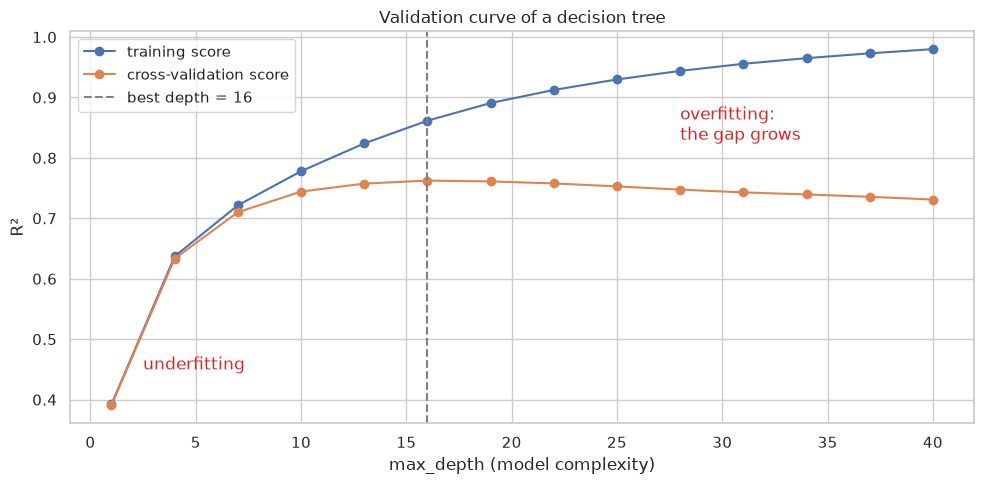

In [28]:
from sklearn.model_selection import validation_curve

depths = np.arange(1, 41, 3)
train_scores, cv_scores = validation_curve(
    house_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE), scale=False),
    X_train, y_train,
    param_name="model__max_depth",   # step name + "__" + parameter name
    param_range=depths,
    cv=cv_regression, scoring="r2", n_jobs=-1,
)

best_depth = depths[cv_scores.mean(axis=1).argmax()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="training score")
ax.plot(depths, cv_scores.mean(axis=1), marker="o", label="cross-validation score")
ax.axvline(best_depth, color="grey", linestyle="--", label=f"best depth = {best_depth}")
ax.annotate("underfitting", xy=(2.5, 0.45), fontsize=12, color="tab:red")
ax.annotate("overfitting:\nthe gap grows", xy=(28, 0.83), fontsize=12, color="tab:red")
ax.set_title("Validation curve of a decision tree")
ax.set_xlabel("max_depth (model complexity)")
ax.set_ylabel("R²")
ax.legend()
plt.tight_layout()
save_fig("04_validation_curve")
plt.show()

The same story as the polynomial example in 1.2, now on real data:
- **Left (shallow trees):** training and validation scores are both low → **underfitting**.
- **Right (deep trees):** the training score keeps climbing towards 1 (the tree memorises the training flats), while the validation score stops improving and slowly **drops** → **overfitting**.
- The best depth is where the **validation** curve peaks. The **gap** between the two curves is a direct measure of overfitting: a model with a training R² of 0.95 and a validation R² of 0.75 has memorised a lot of noise.

💡 **Tip:** with tens of thousands of rows, overfitting is gentle (the validation score drops slowly). With small datasets, like the 768 buildings in Part B, it is much more dramatic.

## 4.6 Hyperparameter tuning with `GridSearchCV`

Instead of trying settings by hand, `GridSearchCV` tries **every combination** in a grid, with cross-validation, and keeps the best one. Thanks to the pipeline, parameter names are `model__<parameter>`. For gradient boosting the two most important knobs are:
- `learning_rate`: how strongly each new tree corrects the previous ones (small = slower, more careful learning).
- `max_leaf_nodes`: how complex each individual tree can be.

The test set is **still locked**: the grid search only uses the training set (with internal cross-validation).

In [29]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__max_iter": [300],   # number of trees (fixed here)
}

start = time.time()
grid_search = GridSearchCV(
    house_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
    param_grid,
    cv=cv_regression,
    scoring="r2",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
print(f"Tried {len(grid_search.cv_results_['params'])} combinations x 5 folds in {time.time() - start:.0f} s")
print("Best settings:", grid_search.best_params_)
print(f"Best cross-validated R²: {grid_search.best_score_:.3f} "
      f"(default settings: {regression_results.loc['Gradient boosting', 'R² mean']:.3f})")

Tried 9 combinations x 5 folds in 60 s
Best settings: {'model__learning_rate': 0.1, 'model__max_iter': 300, 'model__max_leaf_nodes': 63}
Best cross-validated R²: 0.857 (default settings: 0.843)


In [30]:
# The full grid as a table: rows = learning_rate, columns = max_leaf_nodes
grid_table = pd.DataFrame(grid_search.cv_results_["params"])
grid_table["R²"] = grid_search.cv_results_["mean_test_score"]
grid_table.pivot(index="model__learning_rate", columns="model__max_leaf_nodes", values="R²")

model__max_leaf_nodes,15,31,63
model__learning_rate,,,
0.050,0.839,0.848,0.854
0.100,0.847,0.853,0.857
0.200,0.852,0.854,0.855


Tuning usually gives a **modest** gain. Data quality and good features matter much more than hyperparameters. `GridSearchCV` automatically re-trains the best combination on the **whole** training set; it is available as `grid_search.best_estimator_`.

## 4.7 Final evaluation on the test set (once!)

Now, and only now, we unlock the test set. This is our honest estimate of how the model will perform on new flats.

In [31]:
best_house_model = grid_search.best_estimator_
y_pred_test = best_house_model.predict(X_test)

test_report = regression_report(y_test, y_pred_test)
test_report

R² (log scale)    0.854
MAE (₹ Lakh)     19.363
RMSE (₹ Lakh)    34.754
MAPE (%)         21.089
dtype: float64

💡 **Tip:** compare the test R² with the cross-validated R² from the grid search. If they are close, our validation process was reliable (no leakage, no overfitting to the validation folds).

Numbers are important, but **plots** show *where* the model goes wrong. Two classic plots:
- **Predicted vs actual:** a perfect model puts every point on the diagonal.
- **Distribution of the errors:** in percent, so a 10 Lakh error on a cheap flat and on an expensive one are comparable.

Figure saved to figures/05_regression_test_results.png


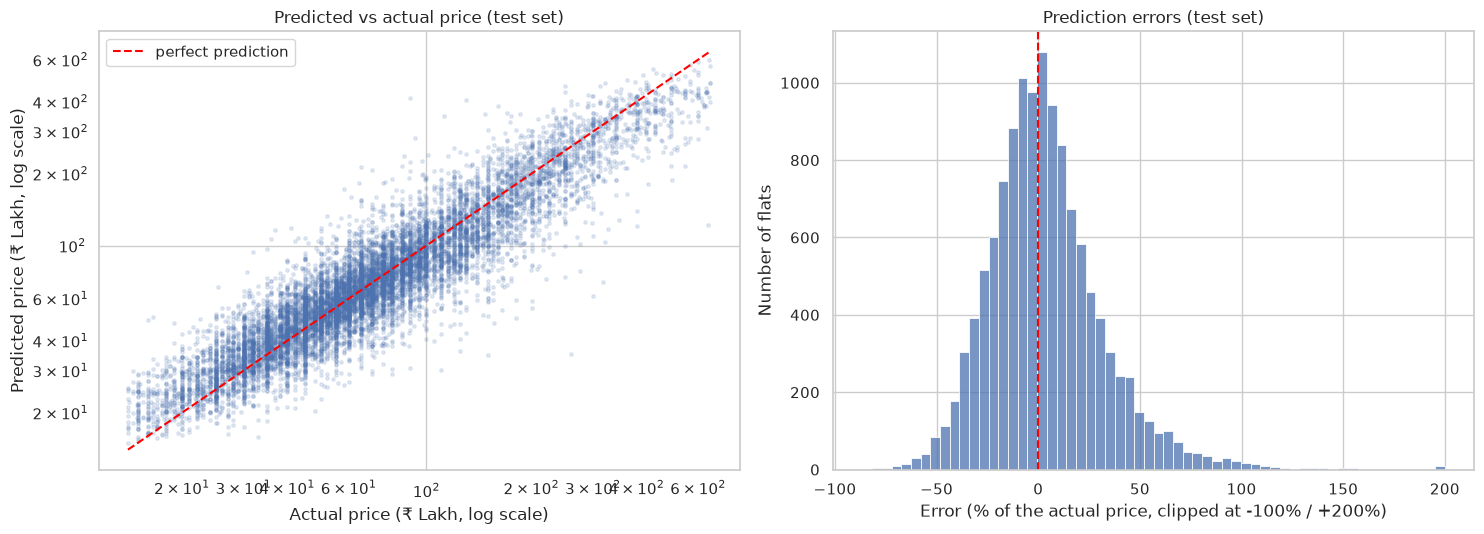

59% of the test flats are predicted within ±20% of their asking price


In [32]:
true_lakh = 10 ** y_test / 1e5
pred_lakh = 10 ** y_pred_test / 1e5
percent_error = (pred_lakh - true_lakh) / true_lakh * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(true_lakh, pred_lakh, alpha=0.15, s=6)
limits = [true_lakh.min(), true_lakh.max()]
axes[0].plot(limits, limits, color="red", linestyle="--", label="perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Predicted vs actual price (test set)")
axes[0].set_xlabel("Actual price (₹ Lakh, log scale)")
axes[0].set_ylabel("Predicted price (₹ Lakh, log scale)")
axes[0].legend()

sns.histplot(percent_error.clip(-100, 200), bins=60, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Prediction errors (test set)")
axes[1].set_xlabel("Error (% of the actual price, clipped at -100% / +200%)")
axes[1].set_ylabel("Number of flats")

plt.tight_layout()
save_fig("05_regression_test_results")
plt.show()

within_20 = (percent_error.abs() <= 20).mean()
print(f"{within_20:.0%} of the test flats are predicted within ±20% of their asking price")

Where does the model struggle? Let's compute the error **per city** (only cities with at least 100 test flats):

In [33]:
errors_by_city = (
    pd.DataFrame({"city": X_test["location"], "abs_pct_error": percent_error.abs()})
    .groupby("city")["abs_pct_error"]
    .agg(["count", "median"])
    .query("count >= 100")
    .sort_values("median")
    .rename(columns={"count": "test flats", "median": "median abs. error (%)"})
)
pd.concat([errors_by_city.head(3), errors_by_city.tail(3)])

,test flats,median abs. error (%)
city,,
Surat,435,11.184
Raipur,104,11.362
Coimbatore,124,11.504
Mumbai,115,24.347
Thane,180,24.368
Chennai,577,25.396


🤔 **Think about it:** why would some cities be harder to predict than others? Think about what our features *don't* describe: the **neighbourhood within the city**, the age and quality of the building, the view from the window… Location inside a city often matters as much as the city itself, and we only have the city name.

## 4.8 Interpretation: which features matter?

Two complementary views:
1. **Linear model coefficients:** for a linear model, each weight tells how much the (log) price changes when a feature increases by one unit (one standard deviation, since we scaled).
2. **Permutation importance:** works for **any** model. We randomly **shuffle** one column of the test set and measure how much the score drops. If shuffling a column destroys the performance, the model relied on it heavily.

In [34]:
# 1) Coefficients of the Ridge model (refit on the full training set)
ridge_pipeline = house_pipeline(Ridge()).fit(X_train, y_train)
coefficients = pd.Series(
    ridge_pipeline.named_steps["model"].coef_,
    index=ridge_pipeline.named_steps["preprocess"].get_feature_names_out(),
)

# Only the numeric features (the 81 city columns would make the plot unreadable)
numeric_coefficients = coefficients[coefficients.index.str.startswith("num__")]
numeric_coefficients.index = numeric_coefficients.index.str.replace("num__", "")
numeric_coefficients.sort_values()

efficiency            -0.005
view_main_road        -0.004
parking_spaces        -0.003
floor_ratio           -0.002
balcony               -0.001
balcony_was_missing   -0.000
view_pool              0.000
floor_num              0.002
view_garden            0.003
carpet_area            0.025
bathroom               0.039
total_floors           0.040
bhk                    0.056
super_area             0.134
dtype: float64

Because the target is log10(price), a coefficient of `0.1` means *"one standard deviation more of this feature multiplies the price by 10^0.1 ≈ 1.26 (+26%), all other features being equal"*.

⚠️ **Watch out:** "all other features being equal" is a strong assumption. `bhk`, `bathroom`, `carpet_area` and `super_area` are strongly correlated (Day 1 heatmap). When features overlap, the model can split their effect between them in odd ways, so a single coefficient can even get the "wrong" sign. Interpret coefficients of correlated features **together**, not one by one.

Now the permutation importance of our best model:

Computed in 6 s
Figure saved to figures/06_house_feature_importance.png


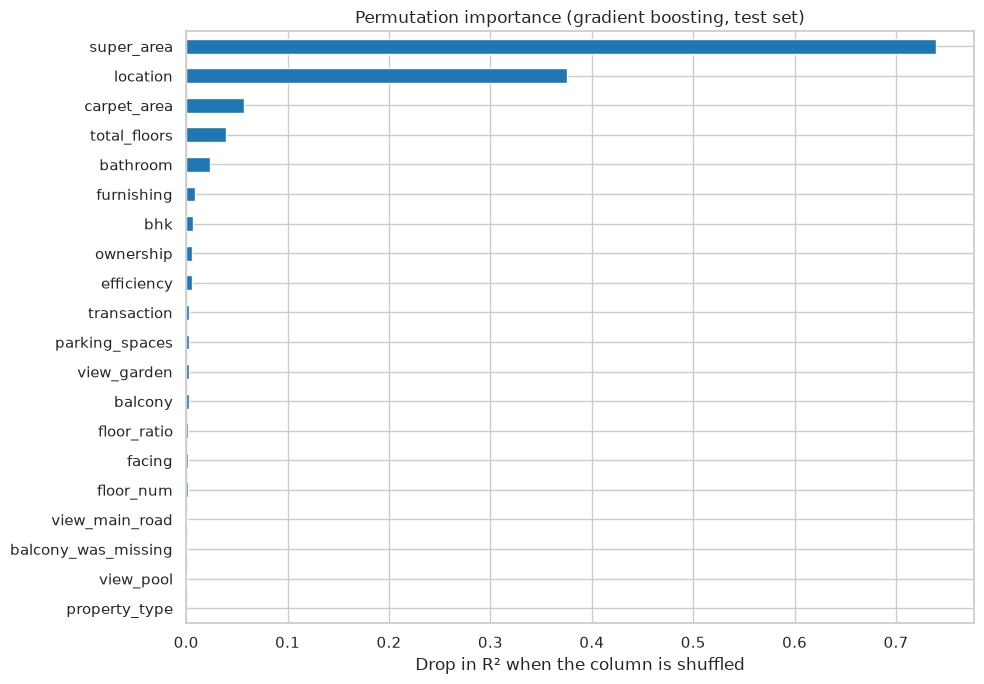

In [35]:
from sklearn.inspection import permutation_importance

start = time.time()
# Use a sample of the test set to keep it fast. n_repeats: shuffle each column 5 times and average
test_sample = X_test.sample(5000, random_state=RANDOM_STATE)
importance = permutation_importance(
    best_house_model, test_sample, y_test.loc[test_sample.index],
    scoring="r2", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
print(f"Computed in {time.time() - start:.0f} s")

importance_house = pd.Series(importance.importances_mean, index=test_sample.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
importance_house.plot.barh(ax=ax, color="tab:blue")
ax.set_title("Permutation importance (gradient boosting, test set)")
ax.set_xlabel("Drop in R² when the column is shuffled")
plt.tight_layout()
save_fig("06_house_feature_importance")
plt.show()

**Reading the plot:** the model relies mostly on **size** (`super_area`, `carpet_area`) and **location**. Design-related features such as `facing`, the views or the floor position add only a little on top. This matches what we saw in the Day 1 EDA: their effect exists but is small compared to *where* and *how big*.

⚠️ **Watch out:** importance says what the **model** uses, not what **causes** the price. And when two features are strongly correlated (`carpet_area` and `super_area`), shuffling one of them hurts less because the model can still use the other: their importance is "shared".

## 4.9 Save the model and use it on a new flat

The pipeline contains *everything*: imputation medians, categories, encoders and the trained trees. We save it to a file, load it back, and use it to estimate the price of a flat that is **not in the dataset**: a design option in an early feasibility study.

In [36]:
model_path = MODEL_DIR / "house_price_gradient_boosting.joblib"
joblib.dump(best_house_model, model_path)
print(f"Model saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Later, or in another notebook / app:
loaded_model = joblib.load(model_path)

Model saved to models/house_price_gradient_boosting.joblib (2.2 MB)


In [37]:
# A design option: a new 2 BHK flat of 85 m² net in Bangalore, 5th floor of a 12-storey building
carpet_sqft = 85 * 10.7639          # m² -> sqft
super_sqft = carpet_sqft / 0.8      # assume a net-to-gross efficiency of 0.8

new_flat = pd.DataFrame([{
    "location": "Bangalore", "bhk": 2, "property_type": "Flat",
    "carpet_area": carpet_sqft, "super_area": super_sqft, "efficiency": 0.8,
    "bathroom": 2, "balcony": 1, "balcony_was_missing": 0,
    "floor_num": 5, "total_floors": 12, "floor_ratio": 5 / 12,
    "facing": "East", "view_garden": 1, "view_pool": 0, "view_main_road": 0,
    "transaction": "New Property", "furnishing": "Semi-Furnished", "ownership": "Freehold",
    "parking_spaces": 1,
}])

price_option_1 = 10 ** loaded_model.predict(new_flat)[0] / 1e5
print(f"Estimated asking price: ₹{price_option_1:,.0f} Lakh")

# What if the same flat faced South-West and overlooked a pool?
variant = new_flat.assign(facing="South-West", view_pool=1)
price_option_2 = 10 ** loaded_model.predict(variant)[0] / 1e5
print(f"Same flat, South-West facing with pool view: ₹{price_option_2:,.0f} Lakh "
      f"({(price_option_2 / price_option_1 - 1) * 100:+.1f}%)")

Estimated asking price: ₹81 Lakh
Same flat, South-West facing with pool view: ₹82 Lakh (+1.1%)


This is how a trained model becomes a **design tool**: change one parameter, see how the estimate moves. Here orientation and view change the estimate by only about 1%: consistent with the permutation importance above (the model learned that these features matter little compared to size and city).

⚠️ **Watch out:** a model is only reliable for inputs **similar to its training data**. A 400 m² penthouse in a city that isn't in the dataset would get a prediction, but nobody should trust it.

### Published on Hugging Face

This exact pipeline is published in the course organization on Hugging Face, with a complete **model card** (features, training data, training procedure, evaluation, limitations and how to use it):

**https://huggingface.co/iaac-maai/day2-example-house-price**

It is the worked example for your Day 2 assignment: your model and its card should look like this. Anyone can download and use it, without this notebook and without retraining:

```python
import joblib
from huggingface_hub import hf_hub_download

path = hf_hub_download(repo_id="iaac-maai/day2-example-house-price", filename="model.joblib")
model = joblib.load(path)
model.predict(new_flat)   # same columns as X_train; returns log10(price in ₹)
```

💡 **Tip:** the brief in `Day_2/submissions/README.md` explains step by step how to publish your own model with the `hf` command-line tool, and what the model card must contain.

# 5. Part B – Classification: predicting the energy class of a building

**Use case:** in the early design phase, an architect explores building **shapes** (compactness, height, roof area) and **glazing** options. A full energy simulation for every option is slow. Can a model trained on simulated buildings instantly tell which **energy class** a design option will reach?

## 5.1 A quick look at the data

The dataset is simulated, so it is already clean: no missing values, no duplicates, all numeric. Let's check which design parameters drive the heating demand.

In [38]:
energy.describe().T

,count,mean,std,min,25%,50%,75%,max
relative_compactness,768.000,0.764,0.106,0.620,0.682,0.750,0.830,0.980
surface_area,768.000,671.708,88.086,514.500,606.375,673.750,741.125,808.500
wall_area,768.000,318.500,43.626,245.000,294.000,318.500,343.000,416.500
roof_area,768.000,176.604,45.166,110.250,140.875,183.750,220.500,220.500
overall_height,768.000,5.250,1.751,3.500,3.500,5.250,7.000,7.000
orientation,768.000,3.500,1.119,2.000,2.750,3.500,4.250,5.000
glazing_area,768.000,0.234,0.133,0.000,0.100,0.250,0.400,0.400
glazing_distribution,768.000,2.812,1.551,0.000,1.750,3.000,4.000,5.000
heating_load,768.000,22.307,10.090,6.010,12.992,18.950,31.668,43.100
cooling_load,768.000,24.588,9.513,10.900,15.620,22.080,33.133,48.030


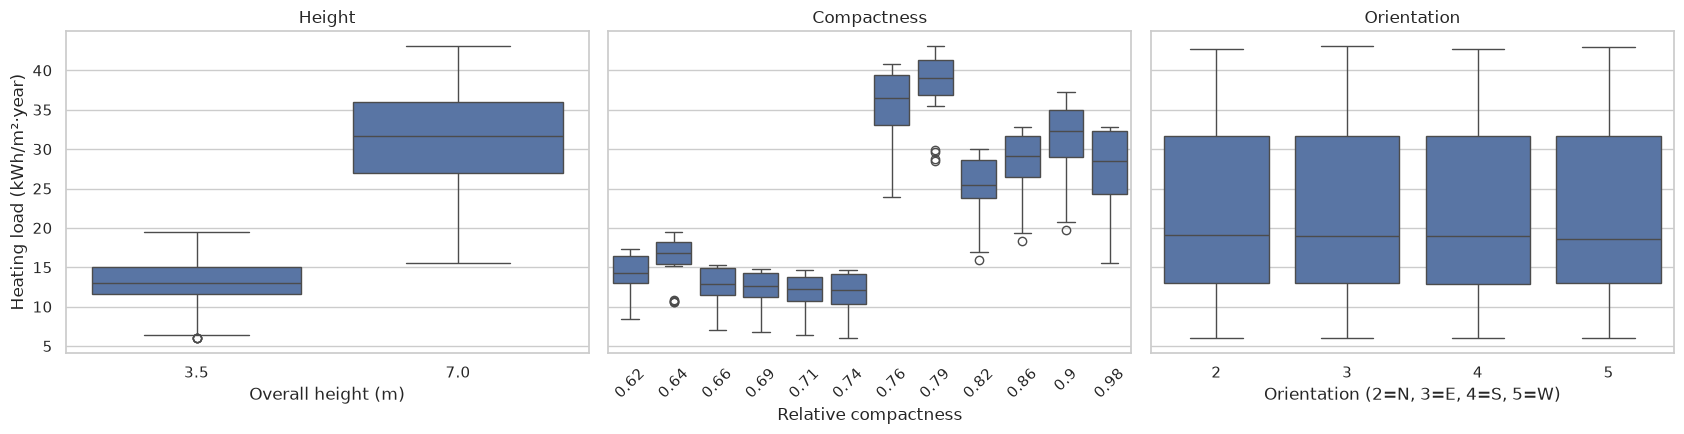

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)

sns.boxplot(data=energy, x="overall_height", y="heating_load", ax=axes[0])
axes[0].set_title("Height")
axes[0].set_xlabel("Overall height (m)")
axes[0].set_ylabel("Heating load (kWh/m²·year)")

sns.boxplot(data=energy, x="relative_compactness", y="heating_load", ax=axes[1])
axes[1].set_title("Compactness")
axes[1].set_xlabel("Relative compactness")
axes[1].tick_params(axis="x", rotation=45)

sns.boxplot(data=energy, x="orientation", y="heating_load", ax=axes[2])
axes[2].set_title("Orientation")
axes[2].set_xlabel("Orientation (2=N, 3=E, 4=S, 5=W)")

plt.tight_layout()
plt.show()

Two-storey buildings (7 m) need far more heating than single-storey ones, and compactness clearly matters. Orientation, on the other hand, seems to make almost no difference. Keep that in mind for section 5.10.

## 5.2 Creating the target: energy classes

Energy performance certificates (EPC) rate buildings in **classes** (A, B, C…) instead of exact numbers, because classes are easier to communicate. We create our own simple rating from the heating load:

| Class | Heating load (kWh/m²·year) | Meaning |
|---|---|---|
| **A** | ≤ 15 | Efficient |
| **B** | 15 – 30 | Average |
| **C** | > 30 | Inefficient |

⚠️ **Watch out – leakage again:** `cooling_load` is computed by the same simulation and is almost perfectly correlated with the heating load. A designer wouldn't know it without running the simulation, so we **remove** it from the features. And of course `heating_load` itself must go too: the class is made from it!

In [40]:
energy["energy_class"] = pd.cut(
    energy["heating_load"],
    bins=[0, 15, 30, np.inf],      # (0, 15], (15, 30], (30, infinity)
    labels=["A", "B", "C"],
).astype(str)

energy_features = ["relative_compactness", "surface_area", "wall_area", "roof_area",
                   "overall_height", "orientation", "glazing_area", "glazing_distribution"]

X_energy = energy[energy_features]
y_energy = energy["energy_class"]

print("Correlation heating vs cooling load:", round(energy["heating_load"].corr(energy["cooling_load"]), 3))
y_energy.value_counts().sort_index()

Correlation heating vs cooling load: 0.976


energy_class
A    285
B    282
C    201
Name: count, dtype: int64

The three classes have similar sizes: the dataset is **balanced**.

**Encoding the target.** As we saw in section 2.3, `LabelEncoder` is the tool designed for **class labels**:

In [41]:
class_encoder = LabelEncoder()
y_energy_codes = class_encoder.fit_transform(y_energy)

print("Classes:", list(class_encoder.classes_))
print("First labels:", list(y_energy[:6]), "->", list(y_energy_codes[:6]))
print("And back:", list(class_encoder.inverse_transform([0, 1, 2])))

Classes: ['A', 'B', 'C']
First labels: ['B', 'B', 'B', 'B', 'B', 'B'] -> [np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1)]
And back: ['A', 'B', 'C']


💡 **Tip:** scikit-learn classifiers also accept **text labels** directly (they encode them internally) and give text back in their predictions. To keep our results readable we will simply use the `"A"/"B"/"C"` strings from now on. You need `LabelEncoder` when a library (e.g. some deep learning frameworks) requires numeric labels.

## 5.3 Stratified train / test split

With classes, we want the training and test sets to have the **same proportion of each class** as the full dataset. Otherwise, by bad luck, the test set could contain almost no class C buildings. This is called a **stratified** split: `stratify=y`.

In [42]:
from sklearn.model_selection import StratifiedKFold

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_energy, y_energy,
    test_size=0.2,
    stratify=y_energy,          # keep the class proportions
    random_state=RANDOM_STATE,
)

# The stratified version of KFold, for cross-validation
cv_classification = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pd.DataFrame({
    "train (%)": ye_train.value_counts(normalize=True).sort_index() * 100,
    "test (%)": ye_test.value_counts(normalize=True).sort_index() * 100,
}).round(1)

,train (%),test (%)
energy_class,,
A,37.100,37.000
B,36.600,37.000
C,26.200,26.000


## 5.4 Classification metrics

Let's train a first model (logistic regression) and look at its errors. To evaluate without touching the test set, we use `cross_val_predict`: every training building gets a prediction from the model trained on the **other** folds (an "out-of-fold" prediction).

In this dataset `orientation` and `glazing_distribution` are numbers but they are **nominal** (more in 5.6), so we one-hot encode them. All other columns are numeric.

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

energy_nominal = ["orientation", "glazing_distribution"]
energy_numeric = [c for c in energy_features if c not in energy_nominal]


def energy_pipeline(model, scale=True, nominal=energy_nominal):
    numeric = [c for c in energy_features if c not in nominal]
    return make_pipeline_for(model, numeric, nominal, scale=scale)


logistic = energy_pipeline(LogisticRegression(max_iter=2000))
ye_pred_oof = cross_val_predict(logistic, Xe_train, ye_train, cv=cv_classification)

### The confusion matrix

The most informative view of a classifier. Rows = the **true** class, columns = the **predicted** class. The **diagonal** contains the correct predictions; everything else is a mistake, and we can see exactly **which** classes get confused.

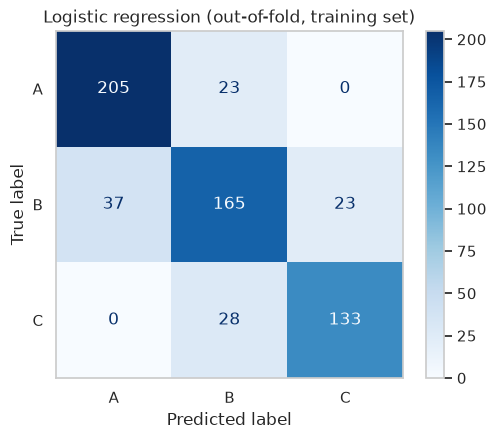

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(ye_train, ye_pred_oof, cmap="Blues", ax=ax)
ax.set_title("Logistic regression (out-of-fold, training set)")
ax.grid(False)
plt.tight_layout()
plt.show()

From the confusion matrix we derive the main metrics. For one class (say **C**, inefficient):

| Metric | Question it answers | Formula (for class C) |
|---|---|---|
| **Accuracy** | What share of **all** predictions is correct? | correct / total |
| **Precision** | When the model says *"C"*, how often is it right? | true C among predicted C |
| **Recall** (sensitivity) | Of all the real C buildings, how many did the model find? | true C found / all real C |
| **F1-score** | A single number balancing precision and recall | harmonic mean of precision and recall |

**Which one matters?** It depends on the **cost of each mistake**:
- A municipality that wants to **find every inefficient building** for a retrofit programme cares about **recall** for class C: missing one is worse than a false alarm.
- A bank offering "green mortgages" only to class A cares about **precision** for class A: approving a building that is not really efficient is the costly mistake.

With several classes, we average the per-class scores: the **macro** average gives every class the same weight; the **weighted** average weights each class by its size. `classification_report` shows everything at once:

In [45]:
from sklearn.metrics import classification_report

print(classification_report(ye_train, ye_pred_oof))

              precision    recall  f1-score   support

           A       0.85      0.90      0.87       228
           B       0.76      0.73      0.75       225
           C       0.85      0.83      0.84       161

    accuracy                           0.82       614
   macro avg       0.82      0.82      0.82       614
weighted avg       0.82      0.82      0.82       614



## 5.5 The accuracy trap

Accuracy looks like the obvious metric, but it can be **very misleading** when classes are **imbalanced**. Let's change the question: *"is this building **very** energy-hungry (heating load > 35)?"*. Only ~15% of the buildings are.

We compare the "dumb" baseline (always answers the most frequent class: *"no"*) with a logistic regression:

In [46]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

very_high = (energy.loc[Xe_train.index, "heating_load"] > 35).map({True: "very high", False: "normal"})
print(very_high.value_counts(normalize=True).round(3))

trap_models = {
    "Baseline (most frequent)": energy_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": energy_pipeline(LogisticRegression(max_iter=2000)),
}

rows = []
for name, model in trap_models.items():
    pred = cross_val_predict(model, Xe_train, very_high, cv=cv_classification)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(very_high, pred),
        # pos_label: the class we care about finding
        "precision (very high)": precision_score(very_high, pred, pos_label="very high", zero_division=0),
        "recall (very high)": recall_score(very_high, pred, pos_label="very high"),
        "F1 (very high)": f1_score(very_high, pred, pos_label="very high"),
    })
pd.DataFrame(rows).set_index("model")

heating_load
normal      0.849
very high   0.151
Name: proportion, dtype: float64


,accuracy,precision (very high),recall (very high),F1 (very high)
model,,,,
Baseline (most frequent),0.849,0.000,0.000,0.000
Logistic regression,0.875,0.605,0.495,0.544


The baseline reaches a high accuracy of about **85%** while finding **zero** of the energy-hungry buildings (recall = 0). A report that only said *"our model is 85% accurate"* would hide a useless model.

> **With imbalanced classes, never report accuracy alone.** Look at the confusion matrix, and at precision, recall and F1 of the class you care about.

### ROC curve and AUC (briefly)

Most classifiers output a **probability**, and we turn it into a yes/no with a **threshold** (0.5 by default). Lowering the threshold finds more positives (higher recall) but raises more false alarms. The **ROC curve** shows this trade-off for every possible threshold, and the **AUC** (area under the curve) summarises it: 0.5 = random guessing, 1.0 = perfect.

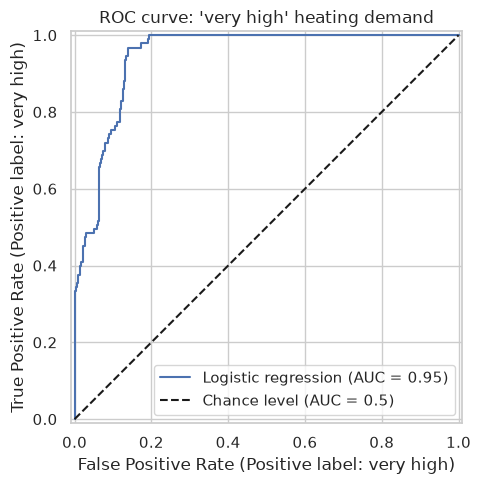

In [47]:
from sklearn.metrics import RocCurveDisplay

# method="predict_proba": out-of-fold probabilities instead of yes/no predictions
proba = cross_val_predict(trap_models["Logistic regression"], Xe_train, very_high,
                          cv=cv_classification, method="predict_proba")
proba_very_high = proba[:, 1]   # columns are sorted alphabetically: ["normal", "very high"]

fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(very_high, proba_very_high, pos_label="very high", ax=ax,
                                 name="Logistic regression", plot_chance_level=True)
ax.set_title("ROC curve: 'very high' heating demand")
plt.tight_layout()
plt.show()

## 5.6 The disguised categorical trap

`orientation` is stored as **2, 3, 4, 5** and `glazing_distribution` as **0–5**. They *look* numeric, so a quick `select_dtypes("number")` would treat them as numbers. But they are **codes for nominal categories**: *West (5)* is not "more orientation" than *North (2)*. This is the same fake-order problem as `LabelEncoder` on features.

Let's compare logistic regression with these two columns treated as **numbers** vs **one-hot encoded**:

In [48]:
disguise_pipelines = {
    "codes treated as numbers": energy_pipeline(LogisticRegression(max_iter=2000), nominal=[]),
    "one-hot encoded": energy_pipeline(LogisticRegression(max_iter=2000)),
}
classification_scoring = {"accuracy": "accuracy", "macro F1": "f1_macro"}

compare_models(disguise_pipelines, Xe_train, ye_train, cv_classification, classification_scoring)

codes treated as numbers done in   0.0 s
one-hot encoded        done in   0.0 s


,accuracy mean,accuracy std,macro F1 mean,macro F1 std,fit time (s)
model,,,,,
codes treated as numbers,0.829,0.037,0.830,0.039,0.014
one-hot encoded,0.819,0.029,0.819,0.032,0.019


Here the difference is tiny (about 0.83 vs 0.82 macro F1) and **smaller than the standard deviation across folds** (≈ 0.03): we cannot say that one version is better. Why? Orientation and glazing distribution have almost no effect on the heating load in this dataset (see the boxplot in 5.1), so *how* we encode them hardly matters.

Compare with `location` in section 4.3: a column that matters a lot, where the fake order cost the linear model about 0.15 of R². The lesson: **the encoding matters most for the columns that matter most**. We keep one-hot encoding, which is correct by construction.

💡 **Tip:** when two results differ by less than their standard deviation, treat them as a tie.

## 5.7 The model zoo on energy classes

The same model families, now in their **classification** versions, built with the **same** helper: pipelines work identically for regression and classification.

In [49]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

classification_pipelines = {
    "Baseline (most frequent)": energy_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": energy_pipeline(LogisticRegression(max_iter=2000)),
    "KNN (k=10)": energy_pipeline(KNeighborsClassifier(n_neighbors=10)),
    "Decision tree": energy_pipeline(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), scale=False),
    "Random forest": energy_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": energy_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}

classification_results = compare_models(classification_pipelines, Xe_train, ye_train,
                                        cv_classification, classification_scoring)
classification_results.sort_values("macro F1 mean", ascending=False)

Baseline (most frequent) done in   0.0 s
Logistic regression    done in   0.0 s
KNN (k=10)             done in   0.0 s
Decision tree          done in   0.0 s
Random forest          done in   0.3 s
Gradient boosting      done in   0.2 s


,accuracy mean,accuracy std,macro F1 mean,macro F1 std,fit time (s)
model,,,,,
Gradient boosting,0.992,0.005,0.992,0.005,0.143
Random forest,0.980,0.010,0.982,0.009,0.245
Decision tree,0.964,0.010,0.963,0.010,0.008
KNN (k=10),0.932,0.027,0.931,0.028,0.008
Logistic regression,0.819,0.029,0.819,0.032,0.022
Baseline (most frequent),0.371,0.003,0.181,0.001,0.011


Figure saved to figures/07_classification_model_comparison.png


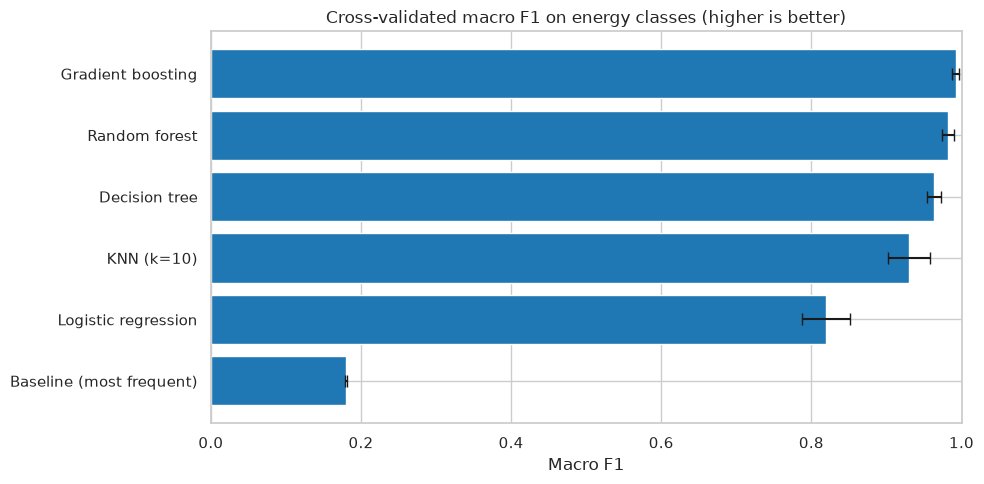

In [50]:
plot_data = classification_results.sort_values("macro F1 mean")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_data.index, plot_data["macro F1 mean"], xerr=plot_data["macro F1 std"], color="tab:blue", capsize=4)
ax.set_xlim(0, 1)
ax.set_title("Cross-validated macro F1 on energy classes (higher is better)")
ax.set_xlabel("Macro F1")
plt.tight_layout()
save_fig("07_classification_model_comparison")
plt.show()

**Reading the results:**
- Every model beats the baseline (macro F1 ≈ 0.18: it always predicts class A, the most frequent one).
- The ranking is **different from Part A**. Logistic regression is clearly the weakest real model (≈ 0.82), while the tree-based models are almost perfect (gradient boosting ≈ 0.99, random forest ≈ 0.98, a single tree ≈ 0.96). The energy class depends on the design parameters in a strongly **non-linear** way, with thresholds and interactions (a jump between one and two storeys, glazing that matters more for some shapes). That is exactly what trees capture with their yes/no questions, and what a weighted sum cannot.
- With only 768 buildings everything trains in a fraction of a second, so speed is no argument here.
- The standard deviations are larger than in Part A (≈ 0.01–0.03), because each validation fold contains only ~120 buildings. Small differences, such as random forest vs gradient boosting, should not be over-interpreted.

🤔 **Think about it:** in Part A the linear model was a respectable second choice; here it is far behind. No model is "the best" in general: the best model depends on the data (machine learning people call this the *no free lunch* theorem). That's why we always compare several.

## 5.8 A model you can read: the decision tree

A big advantage of a (small) decision tree: we can **draw** it and read it as a set of **design rules**. Trees don't need scaling or encoding of these numeric columns, so we train it directly on the raw features.

Figure saved to figures/08_decision_tree.png


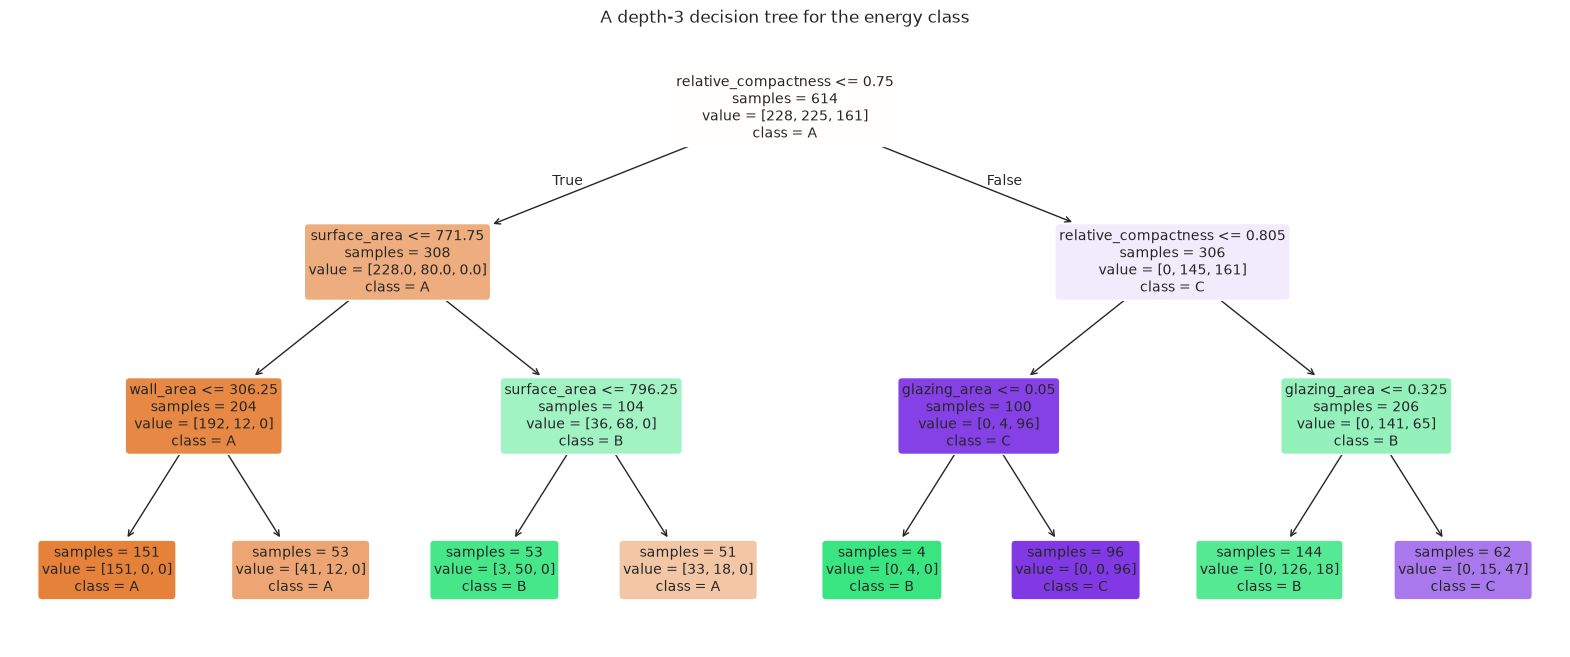

Even this tiny tree reaches a macro F1 of 0.88 on the test set


In [51]:
from sklearn.tree import plot_tree

readable_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
readable_tree.fit(Xe_train, ye_train)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(readable_tree, feature_names=energy_features, class_names=readable_tree.classes_,
          filled=True, rounded=True, impurity=False, fontsize=10, ax=ax)
ax.set_title("A depth-3 decision tree for the energy class")
save_fig("08_decision_tree")
plt.show()

readable_f1 = f1_score(ye_test, readable_tree.predict(Xe_test), average="macro")
print(f"Even this tiny tree reaches a macro F1 of {readable_f1:.2f} on the test set")

**How to read it:** start at the top. Each box asks a question about one feature; go **left if true**, **right if false**. `samples` = number of training buildings reaching that box, `value` = how many of them are in each class (A, B, C), `class` = the majority class, which is the prediction. The colour shows the predicted class; the paler the colour, the more mixed the box.

The first question is about **relative compactness**, followed by the **surface area** and the **glazing area**. Written out, the tree gives design rules like *"compact shape (compactness > 0.81) with a lot of glazing (> 33%) → class C"*. Rules like these can be checked against an architect's intuition, which builds trust in the model.

🤔 **Think about it:** the boxplot in 5.1 suggested that **height** was the key variable, yet the tree never asks about it. In this dataset, each of the 12 shapes has a fixed height and a fixed compactness, so asking about one is (almost) the same as asking about the other: compactness ≤ 0.75 are exactly the single-storey buildings. Correlated features are interchangeable for a model.

## 5.9 Final evaluation on the test set

We pick the best model from the comparison (5.7), train it on the full training set, and evaluate it **once** on the test set.

Best model: Gradient boosting

              precision    recall  f1-score   support

           A       1.00      0.98      0.99        57
           B       0.98      1.00      0.99        57
           C       1.00      1.00      1.00        40

    accuracy                           0.99       154
   macro avg       0.99      0.99      0.99       154
weighted avg       0.99      0.99      0.99       154

Figure saved to figures/09_confusion_matrix.png


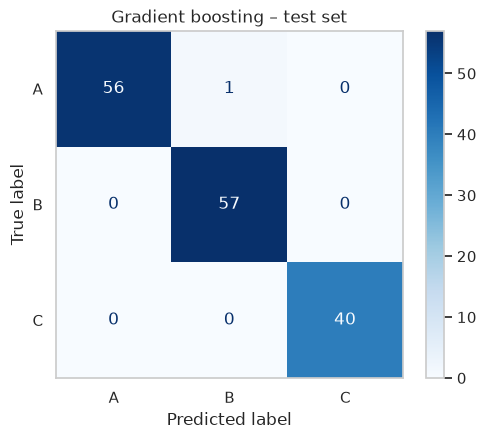

In [52]:
best_name = classification_results.drop(index="Baseline (most frequent)")["macro F1 mean"].idxmax()
best_energy_model = classification_pipelines[best_name].fit(Xe_train, ye_train)
ye_pred_test = best_energy_model.predict(Xe_test)

print(f"Best model: {best_name}\n")
print(classification_report(ye_test, ye_pred_test))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(ye_test, ye_pred_test, cmap="Blues", ax=ax)
ax.set_title(f"{best_name} – test set")
ax.grid(False)
plt.tight_layout()
save_fig("09_confusion_matrix")
plt.show()

The model classifies **153 of the 154** test buildings correctly. The only mistake confuses **neighbouring** classes (an A predicted as B); A and C are never confused. The test score is in line with the cross-validation score, so our validation process was reliable.

⚠️ **Watch out:** near-perfect scores like this are rare in practice. They are possible here because the data is **simulated and noise-free**: the energy class is a fixed function of the 8 design parameters. Measured consumption of real buildings (with occupants, weather and construction quality) would be much noisier, and the scores much lower.

## 5.10 Which design parameters matter?

Permutation importance again, this time with **macro F1** as the score.

Figure saved to figures/10_energy_feature_importance.png


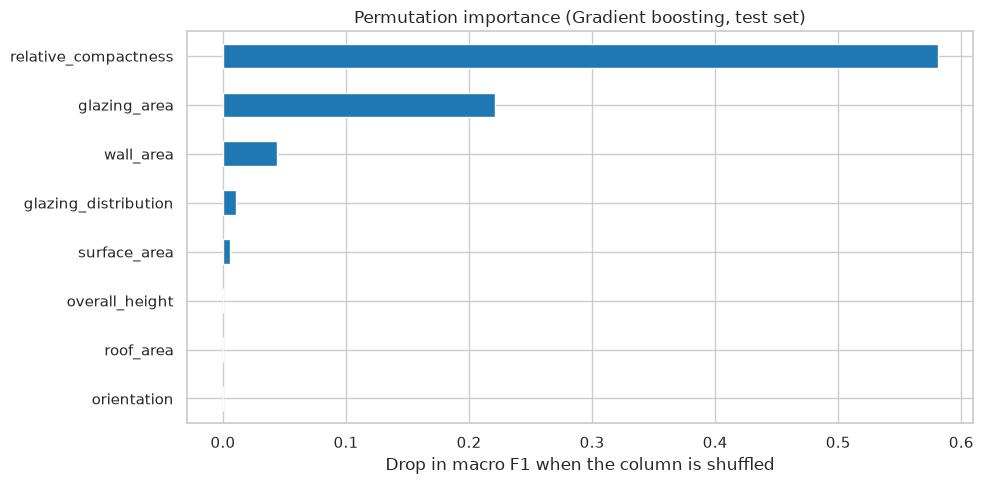

In [53]:
importance = permutation_importance(best_energy_model, Xe_test, ye_test, scoring="f1_macro",
                                    n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_energy = pd.Series(importance.importances_mean, index=Xe_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
importance_energy.plot.barh(ax=ax, color="tab:blue")
ax.set_title(f"Permutation importance ({best_name}, test set)")
ax.set_xlabel("Drop in macro F1 when the column is shuffled")
plt.tight_layout()
save_fig("10_energy_feature_importance")
plt.show()

**Relative compactness** and **glazing area** dominate; wall area and glazing distribution add a little. **Overall height** and **roof area** get an importance of ≈ 0, although the boxplot in 5.1 showed that height has a huge effect on heating!

The reason is **redundancy**, as we saw with the tree in 5.8: compactness, height and roof area describe the same 12 shapes, so when one of them is shuffled, the model simply uses the others.

⚠️ **Watch out:** a low permutation importance means *"the model doesn't need this column, given the other columns"*. It does **not** mean *"this has no effect on energy demand"*. Orientation is ≈ 0 too, and in this case it really has (almost) no effect.

🤔 **Think about it:** in the real world, orientation matters a lot for solar gains and heating. Why is it irrelevant here? In this dataset, each of the 12 shapes is simply **rotated** in 4 directions, and the glazing distribution changes with it; the simulation setup largely cancels out the effect. A model can only learn what is **in the data**. Conclusions drawn from **simulated** data are only as good as the simulation that produced them.

# 6. Summary: which model, which metric?

### Which model?

| Situation | Good first choice | Why |
|---|---|---|
| Any new problem | **Baseline** (`Dummy…`) | Know the score to beat |
| Need to explain the effect of each variable | **Linear / logistic regression** | Each weight has a meaning |
| Need rules a client or a colleague can read | **Small decision tree** | It's a flowchart |
| Tabular data, best accuracy | **Gradient boosting** (or random forest) | State of the art for tables |
| Missing values you don't want to impute | **`HistGradientBoosting…`** | Handles NaN natively |
| "Find similar past projects" | **KNN** | Prediction = similar examples |
| Images, point clouds, text | **Neural networks** | Day 4 |

### Which metric?

| Problem | Metric | Use it when… |
|---|---|---|
| Regression | **MAE** | You want an error in real units that anyone understands |
| Regression | **RMSE** | Large errors are especially costly |
| Regression | **R²** | Comparing models on the same data |
| Regression | **MAPE** | Values span a wide range (prices) and relative errors matter |
| Classification | **Accuracy** | Classes are balanced and all errors cost the same |
| Classification | **Precision** | False alarms are costly |
| Classification | **Recall** | Missing a positive is costly |
| Classification | **F1 / macro F1** | You need one number that balances both, especially with imbalance |
| Classification | **Confusion matrix** | Always! It shows *which* mistakes happen |

### Checklist for an honest evaluation
- [ ] Split the data **first**, lock the test set away
- [ ] Compare against a **baseline**
- [ ] Put all preprocessing **inside a pipeline** (no leakage)
- [ ] Use **cross-validation** to compare and tune models; report mean **±** standard deviation
- [ ] Check for **leakage**: a "perfect" score is a red flag
- [ ] Choose metrics that match the **cost of the mistakes** in your use case
- [ ] Evaluate on the test set **once**, at the end
- [ ] **Interpret**: which features matter, where does the model fail?

# 7. Your turn

1. **Regression on buildings.** Use the energy dataset to predict the **cooling load** (a number) from the 8 design features. Compare a linear regression and a random forest with cross-validation. Which metric would you report to an engineer, and why? (Hint: `make_pipeline_for`, `compare_models`, `KFold`.)
2. **Classification on flats.** Use the house data to predict `transaction` (*New Property* vs *Resale*, about 26% / 74%). Remove `transaction` from the features first! Compare a baseline and a gradient boosting classifier with accuracy **and** F1 for the *New Property* class. What does the baseline's accuracy tell you?
3. **Tuning.** Pick one model from Part B and tune one or two of its hyperparameters with `GridSearchCV`. Is the improvement larger than the standard deviation across folds? Is it worth it?

In [54]:
# 1. Regression on buildings

In [55]:
# 2. Classification on flats

In [56]:
# 3. Tuning

# 8. Conclusions and next steps

### Key findings
- **Leakage is easy to create and easy to miss.** Adding `price_per_sqft` gave a "perfect" R² of 1.000 instead of 0.61. A perfect score is a red flag.
- **Pipelines and encoders matter.** Encoding `location` with fake integer codes cost the linear model about 0.15 of R² (0.78 → 0.63), while gradient boosting barely noticed.
- **House prices (regression):** tree ensembles were best (R² ≈ 0.85 on log-price). Gradient boosting matched the random forest at more than ten times the speed, so we tuned and kept it. On the untouched test set: **R² 0.85, MAPE ≈ 21%**, and about 59% of the flats predicted within ±20% of their asking price. The linear model (R² 0.78) is a respectable, interpretable alternative.
- **What drives the price:** size (`super_area`) and **city** dominate; orientation, views and floor position add little. The hardest cities to predict are large, very heterogeneous markets such as **Mumbai**, Thane and Chennai, where the neighbourhood matters as much as the city.
- **Energy classes (classification):** non-linear models win clearly (gradient boosting macro F1 ≈ 0.99 vs 0.82 for logistic regression), and the final model misclassified only 1 of 154 test buildings, on simulated, noise-free data. Compactness and glazing area are the key design levers; orientation has no effect in this simulation.
- **Metrics:** a baseline reached about 85% accuracy on the "very high demand" question while finding none of those buildings. Choose the metric that matches the cost of the mistakes.

### Limitations
- **House prices:** asking prices, no information about the neighbourhood, building age or quality; the model is only valid for Indian cities in the dataset.
- **Energy:** simulated buildings with one climate and 12 shapes; real buildings have occupants, construction defects and much more variety.
- **Metrics are estimates:** another random split would give slightly different numbers. That is why we report cross-validation means **and** standard deviations.

### From notebook to deliverable
For your assignment repository (see the Day 1 checklist), add:
- The **use case**: what do you predict, for whom, and which mistakes are costly (this decides your metric!).
- A **model comparison table** with a baseline and cross-validated scores.
- The **final test results** and at least one diagnostic plot (predicted vs actual, or confusion matrix).
- Optionally, the **saved model** (`models/*.joblib`) and a short example of how to use it.

### Next: Day 3 – unsupervised learning
Today every example came with an answer (`y`). What if we only have `X`? On Day 3 we let the algorithms find **structure by themselves**: groups of similar buildings (clustering) and compact representations of many variables (dimensionality reduction).

### References
- scikit-learn user guide: [Supervised learning](https://scikit-learn.org/stable/supervised_learning.html), [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html), [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html), [Encoding categorical features](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features)
- scikit-learn: [Choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html)
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), O'Reilly. Chapters 2–7.
- Tsanas, A., Xifara, A. (2012). Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools. *Energy and Buildings*, 49, 560–567.